# Integrative Industry Synthesis: ML, GenAI, and Agentic
## In this notebook (Step-2)
- we will use __SDV__ (Synthetic Data Vault) library, to train two generative models:__TVAE__ and __CTGAN__
- We use full dataset (not just training data of minority class for oversampling)
- We train separate models for minority and majority class. Overall four generative models:
    1. __TVAE0__: TVAE on class=0 (Majority: Legit)
    2. __TVAE1__: TVAE on class=1 (Minority: Fraud)
    3. __CTGAN0__: CTGAN on class=0 (Majority: Legit)
    4. __CTGAN1__: CTGAN on class=1 (Minority: Fraud)
- __SDV__ (Synthetic Data Vault: https://github.com/sdv-dev) also provides __SDMetrics__(Synthetic data evaluation metrics), which we are using for numerical evaluation of generative models

# Setup

## Import required modules

In [1]:
from pathlib import Path
import time
import sys
SRC_DIR = str(Path.cwd().parent /'src')
if SRC_DIR not in sys.path:
    sys.path.append(SRC_DIR)
notebook_start_time = time.time() # Start the global timer
print(f'notebook_start_time={time.ctime(notebook_start_time)}')

notebook_start_time=Fri Oct  9 19:46:25 2026


In [2]:
import importlib
from config import settings
import utils as ut #use importlib.reload(ut) if reload needed in specific cell during development
import utils_gen as ut_gen
import seaborn as sns
import random
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib # for version check
import matplotlib.pyplot as plt
import torch
from collections import Counter
import joblib

from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
# Enable high-resolution Retina plots
%config InlineBackend.figure_format = 'retina'

In [3]:
print("*" * 75)
print(f'PYTHON VERSION:      {sys.version}')
print(f'PYTHON VPATH:        {sys.executable}')
print(f"Pandas version:      {pd.__version__}")
print(f"NumPy version:       {np.__version__}")
print(f"Matplotlib version:  {matplotlib.__version__}")
print(f"Seaborn version:     {sns.__version__}")
print("*" * 75)

***************************************************************************
PYTHON VERSION:      3.13.14 (main, Jul 23 2026, 14:44:45) [Clang 22.1.3 ]
PYTHON VPATH:        /home/max/x/zc07-ml-genai-agentic/.venv/bin/python
Pandas version:      2.3.3
NumPy version:       2.5.3
Matplotlib version:  3.11.2
Seaborn version:     0.13.2
***************************************************************************


In [4]:
print(f'Torch version: {torch.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')
print(f'CUDA version used: {torch.version.cuda}')

Torch version: 2.14.1+cu130
CUDA available: True
CUDA version used: 13.0


In [5]:
def seed_all(seed:int=42):
    """
    set random seed and cuda related settings for reproducibility
    Args:
        seed: int setting the seed
    Return:
        None
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
#---------------------------------------------
seed_all(settings.RANDOM_SEED)

# Ingestion

## Load Cleaned Dataset

In [6]:
df = pd.read_csv(settings.DATA_DIR/settings.DATASET_FILE_CLEANED)
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class,Hour/2
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0,0
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0,0
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0,0
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0,0
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0,0


# Cleaning

## Check for duplicate

In [7]:
ut.check_duplicate(df)

Total duplicate rows: 3440 (1.2%)


In [8]:
print(f"Total duplicates: {df.duplicated().sum()}")
print(f"Fraud duplicates: {df[df['Class'] == 1].duplicated().sum()}")
print(f"Non-Fraud duplicates: {df[df['Class'] == 0].duplicated().sum()}")

Total duplicates: 3440
Fraud duplicates: 0
Non-Fraud duplicates: 3440


# Note
- Because of our feature engineering converting elapsed-time in sec to hour and then hour/2 seems some duplicate data generated
- Fortunately these duplicates are not in fraud class
- Drop this duplicate too

In [9]:
col_counts = df['Class'].value_counts().reset_index()
col_counts['count%']=100*col_counts['count']/col_counts['count'].sum()
print(f'counts Before removing duplicates')
col_counts

counts Before removing duplicates


,Class,count,count%
0,0,283253,99.83329
1,1,473,0.16671


In [10]:
df=ut.remove_duplicate(df)

number of rows Before and After removing duplicates: Before = 283726,  After = 280286


In [11]:
col_counts = df['Class'].value_counts().reset_index()
col_counts['count%']=100*col_counts['count']/col_counts['count'].sum()
print(f'counts After removing duplicates')
col_counts

counts After removing duplicates


,Class,count,count%
0,0,279813,99.831244
1,1,473,0.168756


## Check for Null

In [12]:
ut.check_nan_values(df)

No missing (NaN) values in dataset
++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


# ML

In [13]:
L0=len(df[df['Class']==0])
L1=len(df[df['Class']==1])
class_ratio_01=L0/L1
print(f'Legit-len: L0={L0},\tFraud-len: L1={L1},\tclass-ratio: class_ratio_01={class_ratio_01:.1f}')

Legit-len: L0=279813,	Fraud-len: L1=473,	class-ratio: class_ratio_01=591.6


In [14]:
target_col='Class'
T=settings.HOURS_IN_TIME_GROUP
categorical_cols=[f'Hour/{T}']
feature_cols = [c for c in df.columns if c != target_col]
extF='_F'

In [15]:
model_dic={}

# TVAE1: TVAE for class-1 (minority-class)

In [16]:
tag='TVAE1'
model = ut_gen.get_model_for_synthesizer(df, class_label=1, synthesizer='tvae', ext=extF)
model_dic[tag]=model

Loading TVAE model for minority-Class from /home/max/x/zc07-ml-genai-agentic/data/ml_models/tvae_minority_model_F.pkl


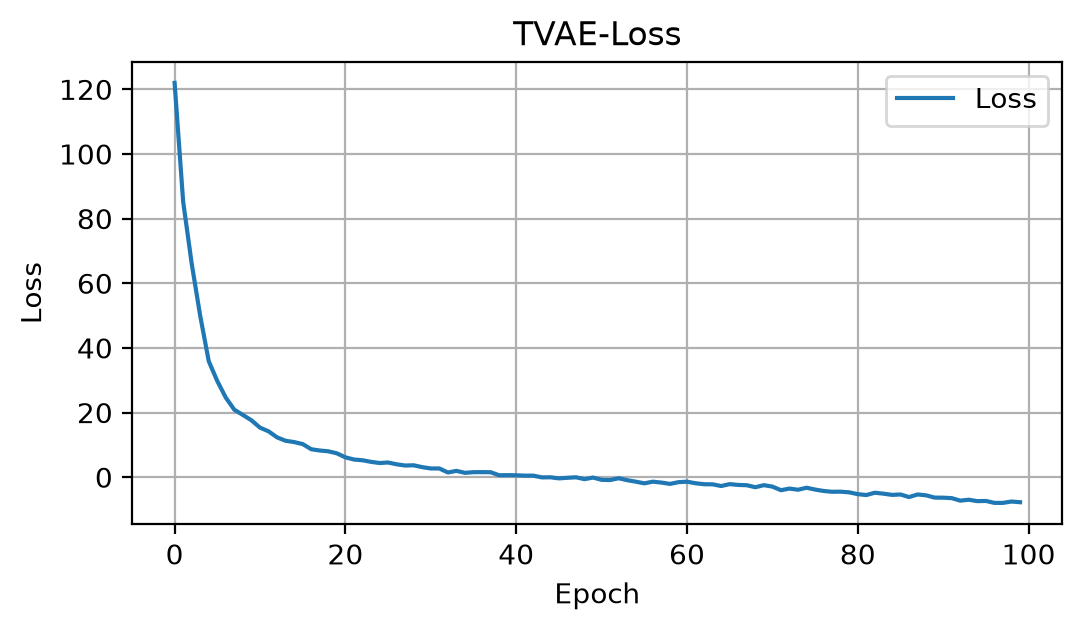

In [17]:
(model.get_loss_values().groupby(['Epoch'], as_index=False)['Loss'].mean()).plot(x='Epoch', grid=True, figsize=(6,3), ylabel='Loss', title='TVAE-Loss');

# CTGAN1: CTGAN for class-1 (minority-class)

In [18]:
tag='CTGAN1'
model = ut_gen.get_model_for_synthesizer(df, class_label=1, synthesizer='ctgan', ext=extF)
model_dic[tag]=model

Loading CTGAN model for minority-Class from /home/max/x/zc07-ml-genai-agentic/data/ml_models/ctgan_minority_model_F.pkl


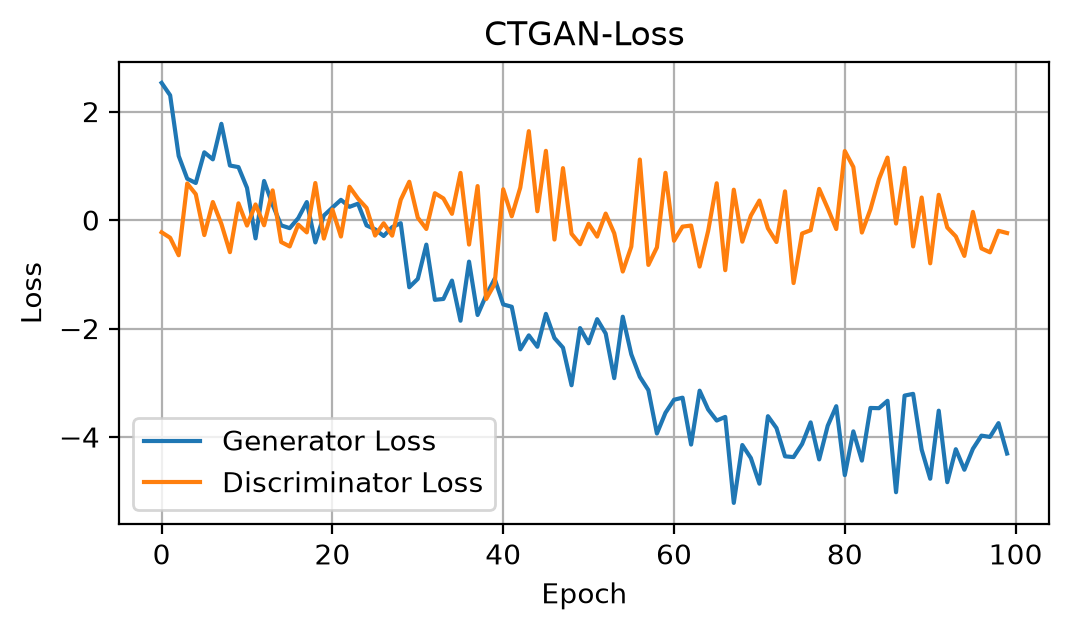

In [19]:
#model.get_loss_values_plot().show()
model.get_loss_values().plot(x='Epoch', grid=True, figsize=(6,3), ylabel='Loss', title='CTGAN-Loss');

# TVAE0: TVAE for class-0 (majority-class)

In [20]:
%%time
tag='TVAE0'
model = ut_gen.get_model_for_synthesizer(df, class_label=0, synthesizer='tvae', ext=extF)
model_dic[tag]=model

Loading TVAE model for majority-Class from /home/max/x/zc07-ml-genai-agentic/data/ml_models/tvae_majority_model_F.pkl
CPU times: user 39.8 ms, sys: 4.73 ms, total: 44.6 ms
Wall time: 40.9 ms


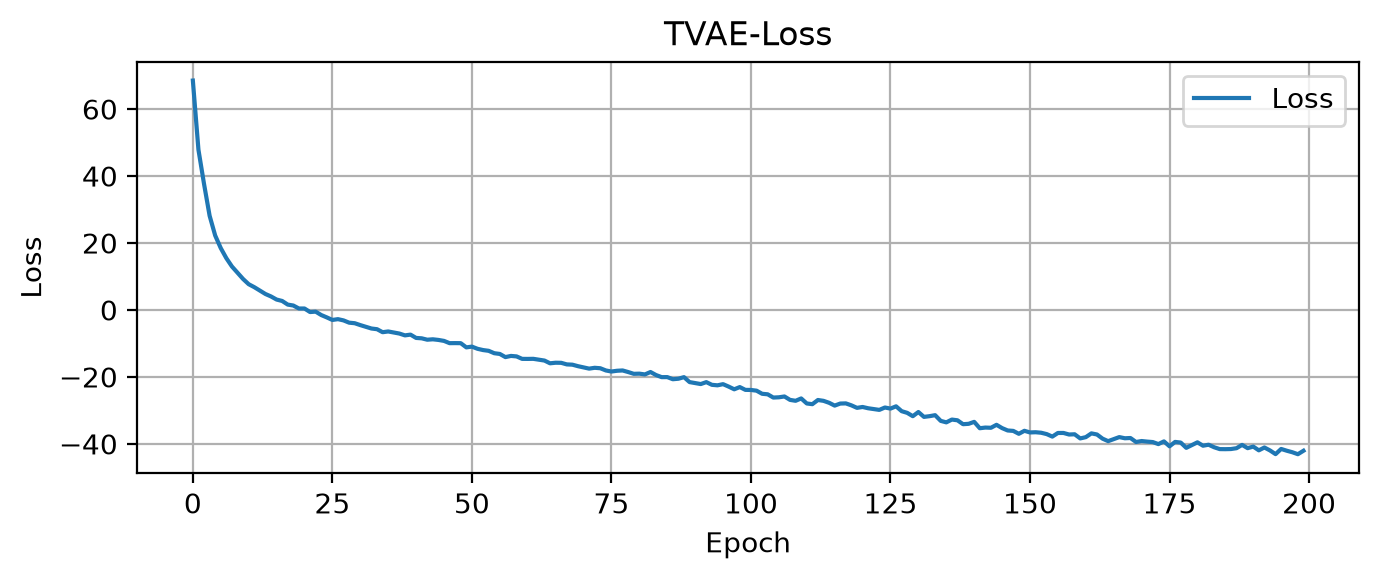

In [21]:
(model.get_loss_values().groupby(['Epoch'], as_index=False)['Loss'].mean()).plot(x='Epoch', grid=True, figsize=(7,3), ylabel='Loss', title='TVAE-Loss');
plt.tight_layout()
plt.savefig(settings.IMG_DIR/'tvae_loss_majority.png', dpi=600)

# CTGAN0: CTGAN for class-0 (majority-class)

In [22]:
importlib.reload(ut_gen);

In [23]:
%%time
tag='CTGAN0'
model = ut_gen.get_model_for_synthesizer(df, class_label=0, synthesizer='ctgan', ext=extF)
model_dic[tag]=model

Loading CTGAN model for majority-Class from /home/max/x/zc07-ml-genai-agentic/data/ml_models/ctgan_majority_model_F.pkl
CPU times: user 38.3 ms, sys: 29 μs, total: 38.3 ms
Wall time: 38.2 ms


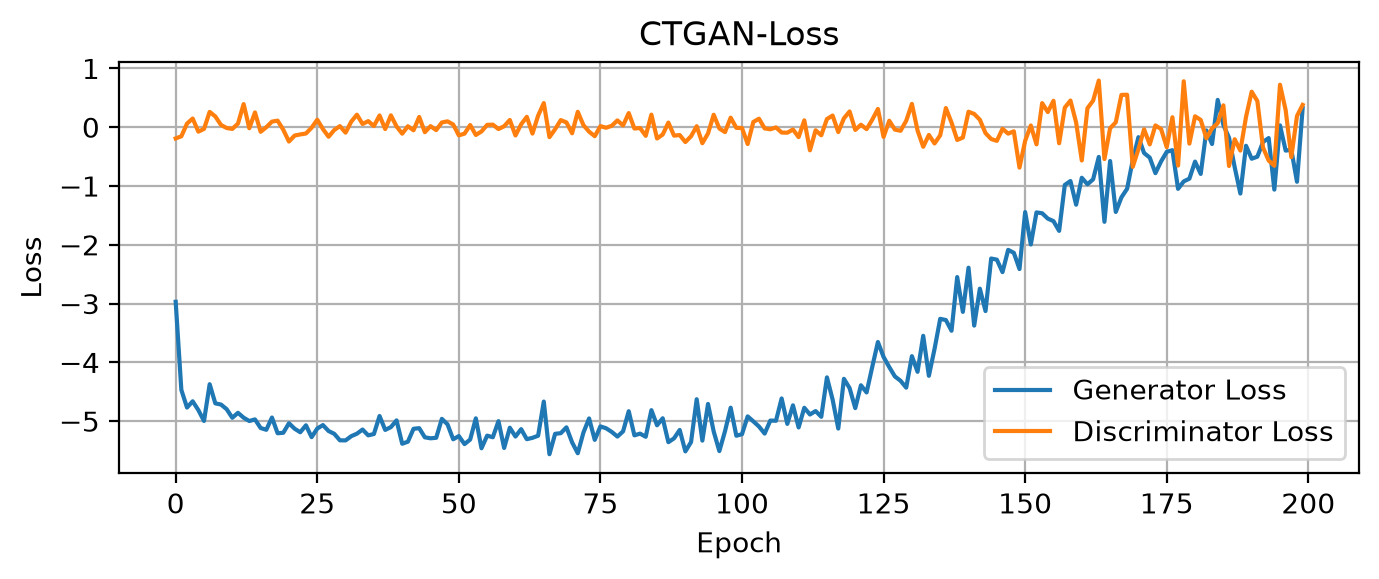

In [24]:
model.get_loss_values().plot(x='Epoch', grid=True, figsize=(7,3), ylabel='Loss', title='CTGAN-Loss');
plt.tight_layout()
plt.savefig(settings.IMG_DIR/'ctgan_loss_majority.png', dpi=600)

# TVAE0 + TVAE1

In [25]:
dft0 = ut_gen.get_sample_form_synthesizer(model_dic['TVAE0'], num_rows=L0, feature_cols=feature_cols, class_label=0, synthesizer='tvae', ext=extF)
dft1 = ut_gen.get_sample_form_synthesizer(model_dic['TVAE1'], num_rows=L1, feature_cols=feature_cols, class_label=1, synthesizer='tvae', ext=extF)
dft=pd.concat([dft0,dft1])

Loading TVAE Scaler for majority-Class from /home/max/x/zc07-ml-genai-agentic/data/ml_models/tvae_majority_scaler_F.pkl
Start Generating 279813 samples ...
Loading TVAE Scaler for minority-Class from /home/max/x/zc07-ml-genai-agentic/data/ml_models/tvae_minority_scaler_F.pkl
Start Generating 473 samples ...


# CTGAN0 + CTGAN1

In [26]:
dfc0 = ut_gen.get_sample_form_synthesizer(model_dic['CTGAN0'], num_rows=L0, feature_cols=feature_cols, class_label=0, synthesizer='ctgan', ext=extF)
dfc1 = ut_gen.get_sample_form_synthesizer(model_dic['CTGAN1'], num_rows=L1, feature_cols=feature_cols, class_label=1, synthesizer='ctgan', ext=extF)
dfc=pd.concat([dfc0,dfc1])

Loading CTGAN Scaler for majority-Class from /home/max/x/zc07-ml-genai-agentic/data/ml_models/ctgan_majority_scaler_F.pkl
Start Generating 279813 samples ...
Loading CTGAN Scaler for minority-Class from /home/max/x/zc07-ml-genai-agentic/data/ml_models/ctgan_minority_scaler_F.pkl
Start Generating 473 samples ...


# 2D Visualization using t-SNE

Running t-SNE... 
Running t-SNE... 
Running t-SNE... 


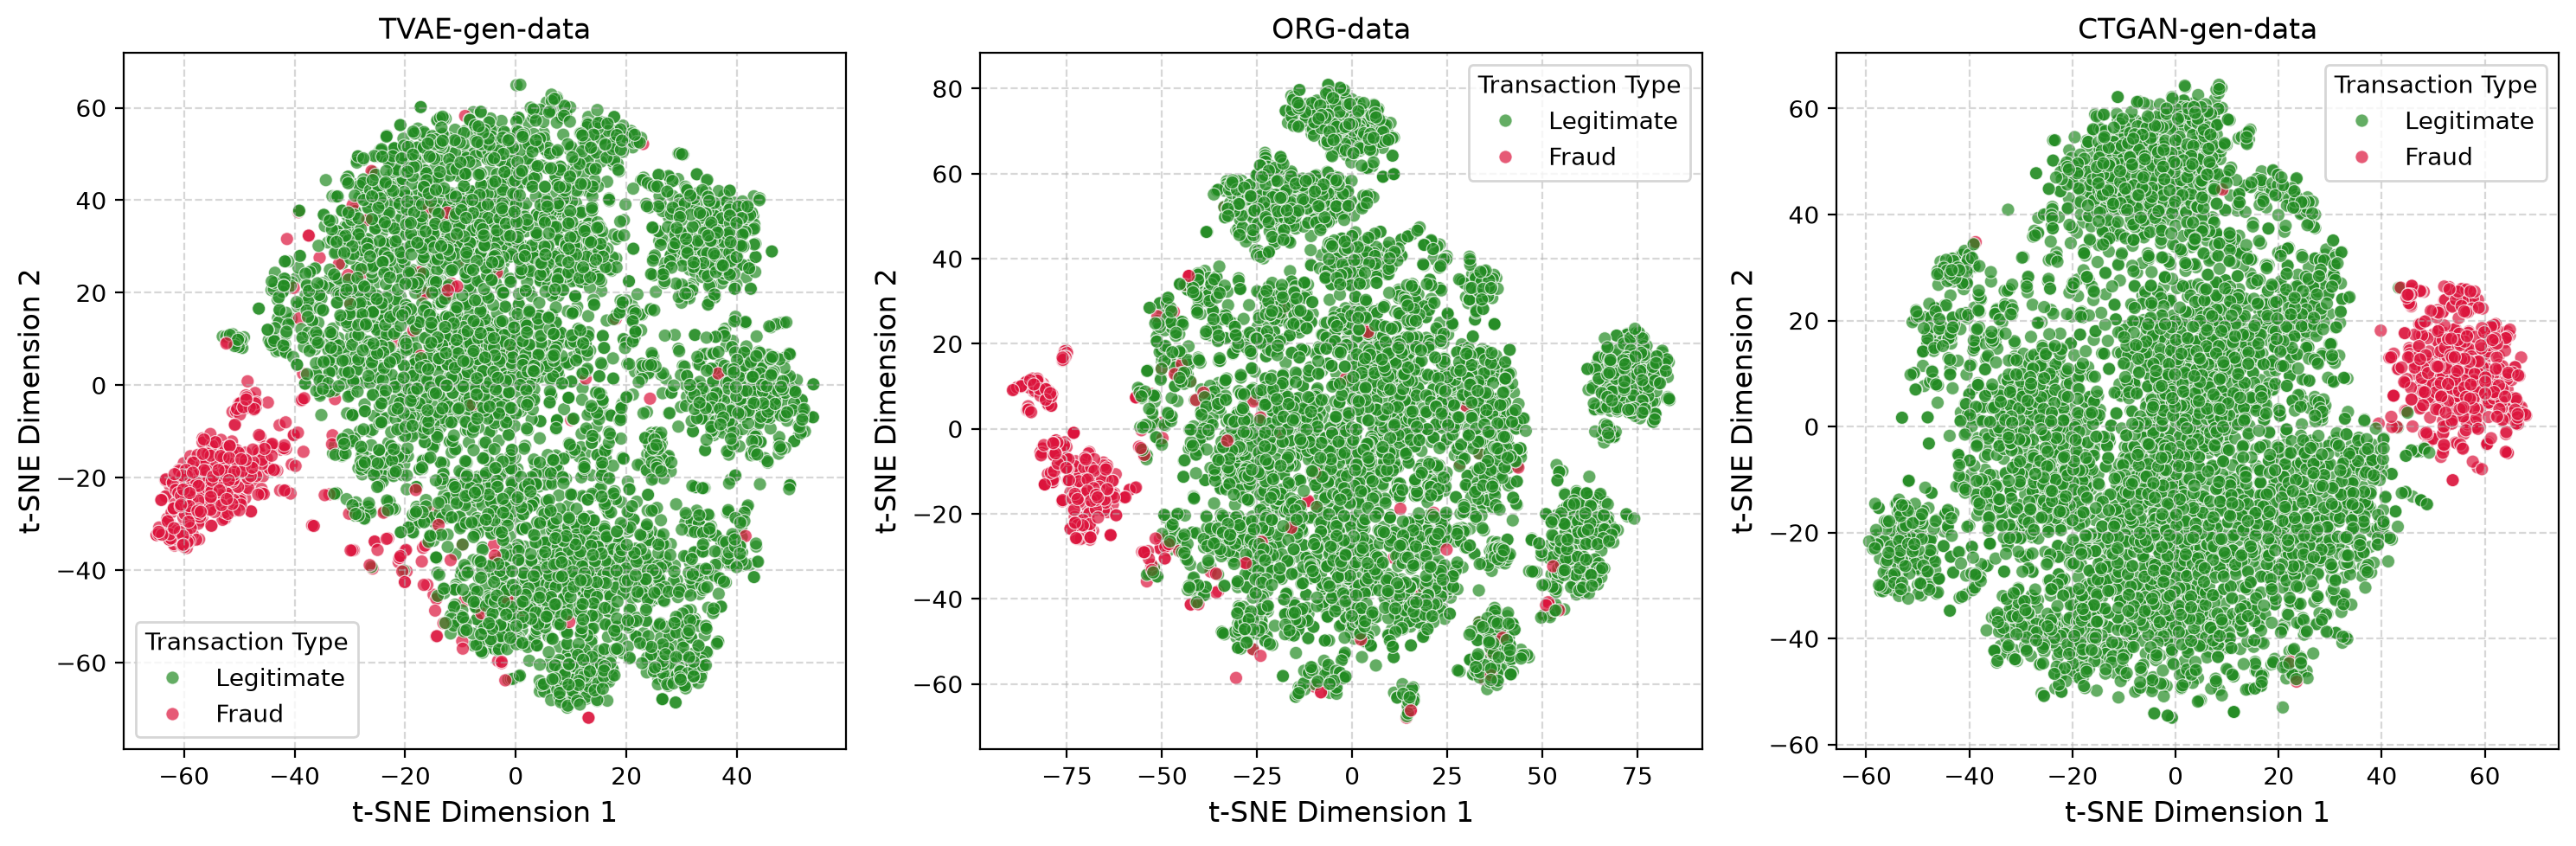

In [27]:
N=5000
fig, axs = plt.subplots(1,3,figsize=(15,5))
ut.plot_2d_visualization_for_binary_class_using_tsne(dft, max_class_samples=N, ext_ax=axs[0])
ut.plot_2d_visualization_for_binary_class_using_tsne(df, max_class_samples=N, ext_ax=axs[1])
ut.plot_2d_visualization_for_binary_class_using_tsne(dfc, max_class_samples=N, ext_ax=axs[2])
axs[0].set_title('TVAE-gen-data')
axs[1].set_title('ORG-data')
axs[2].set_title('CTGAN-gen-data')
plt.tight_layout()
plt.savefig(settings.IMG_DIR/'t-SNE3.png', dpi=600)

NOTE:
- Both Original and Generated data have on big cluster of Legitimate transaction,
- They also have a small cluster of fraud group mainly outside of main cluster
- In t-SNE plot TVAE look much similar the original data because of the underlying VAE (usual mean-square-error loss plus regularization for normality of latent space)
- In t-SNE plot CTGAN fraud group location seems very different, while this is not determining if CTGAN is bad or good, this is related to how t-SNE visualize data, and also how GAN in general is different from VAE in training (It's a game theory and competition between Generator and Discriminator when minimizing the loss) 

# Visual comparison of Distribution per feature

In [28]:
mn=len(df.columns)
n=6
m=mn//n
feat_cols=[c for c in  df.columns if c != 'Class']

## Fraud-Class Distributions

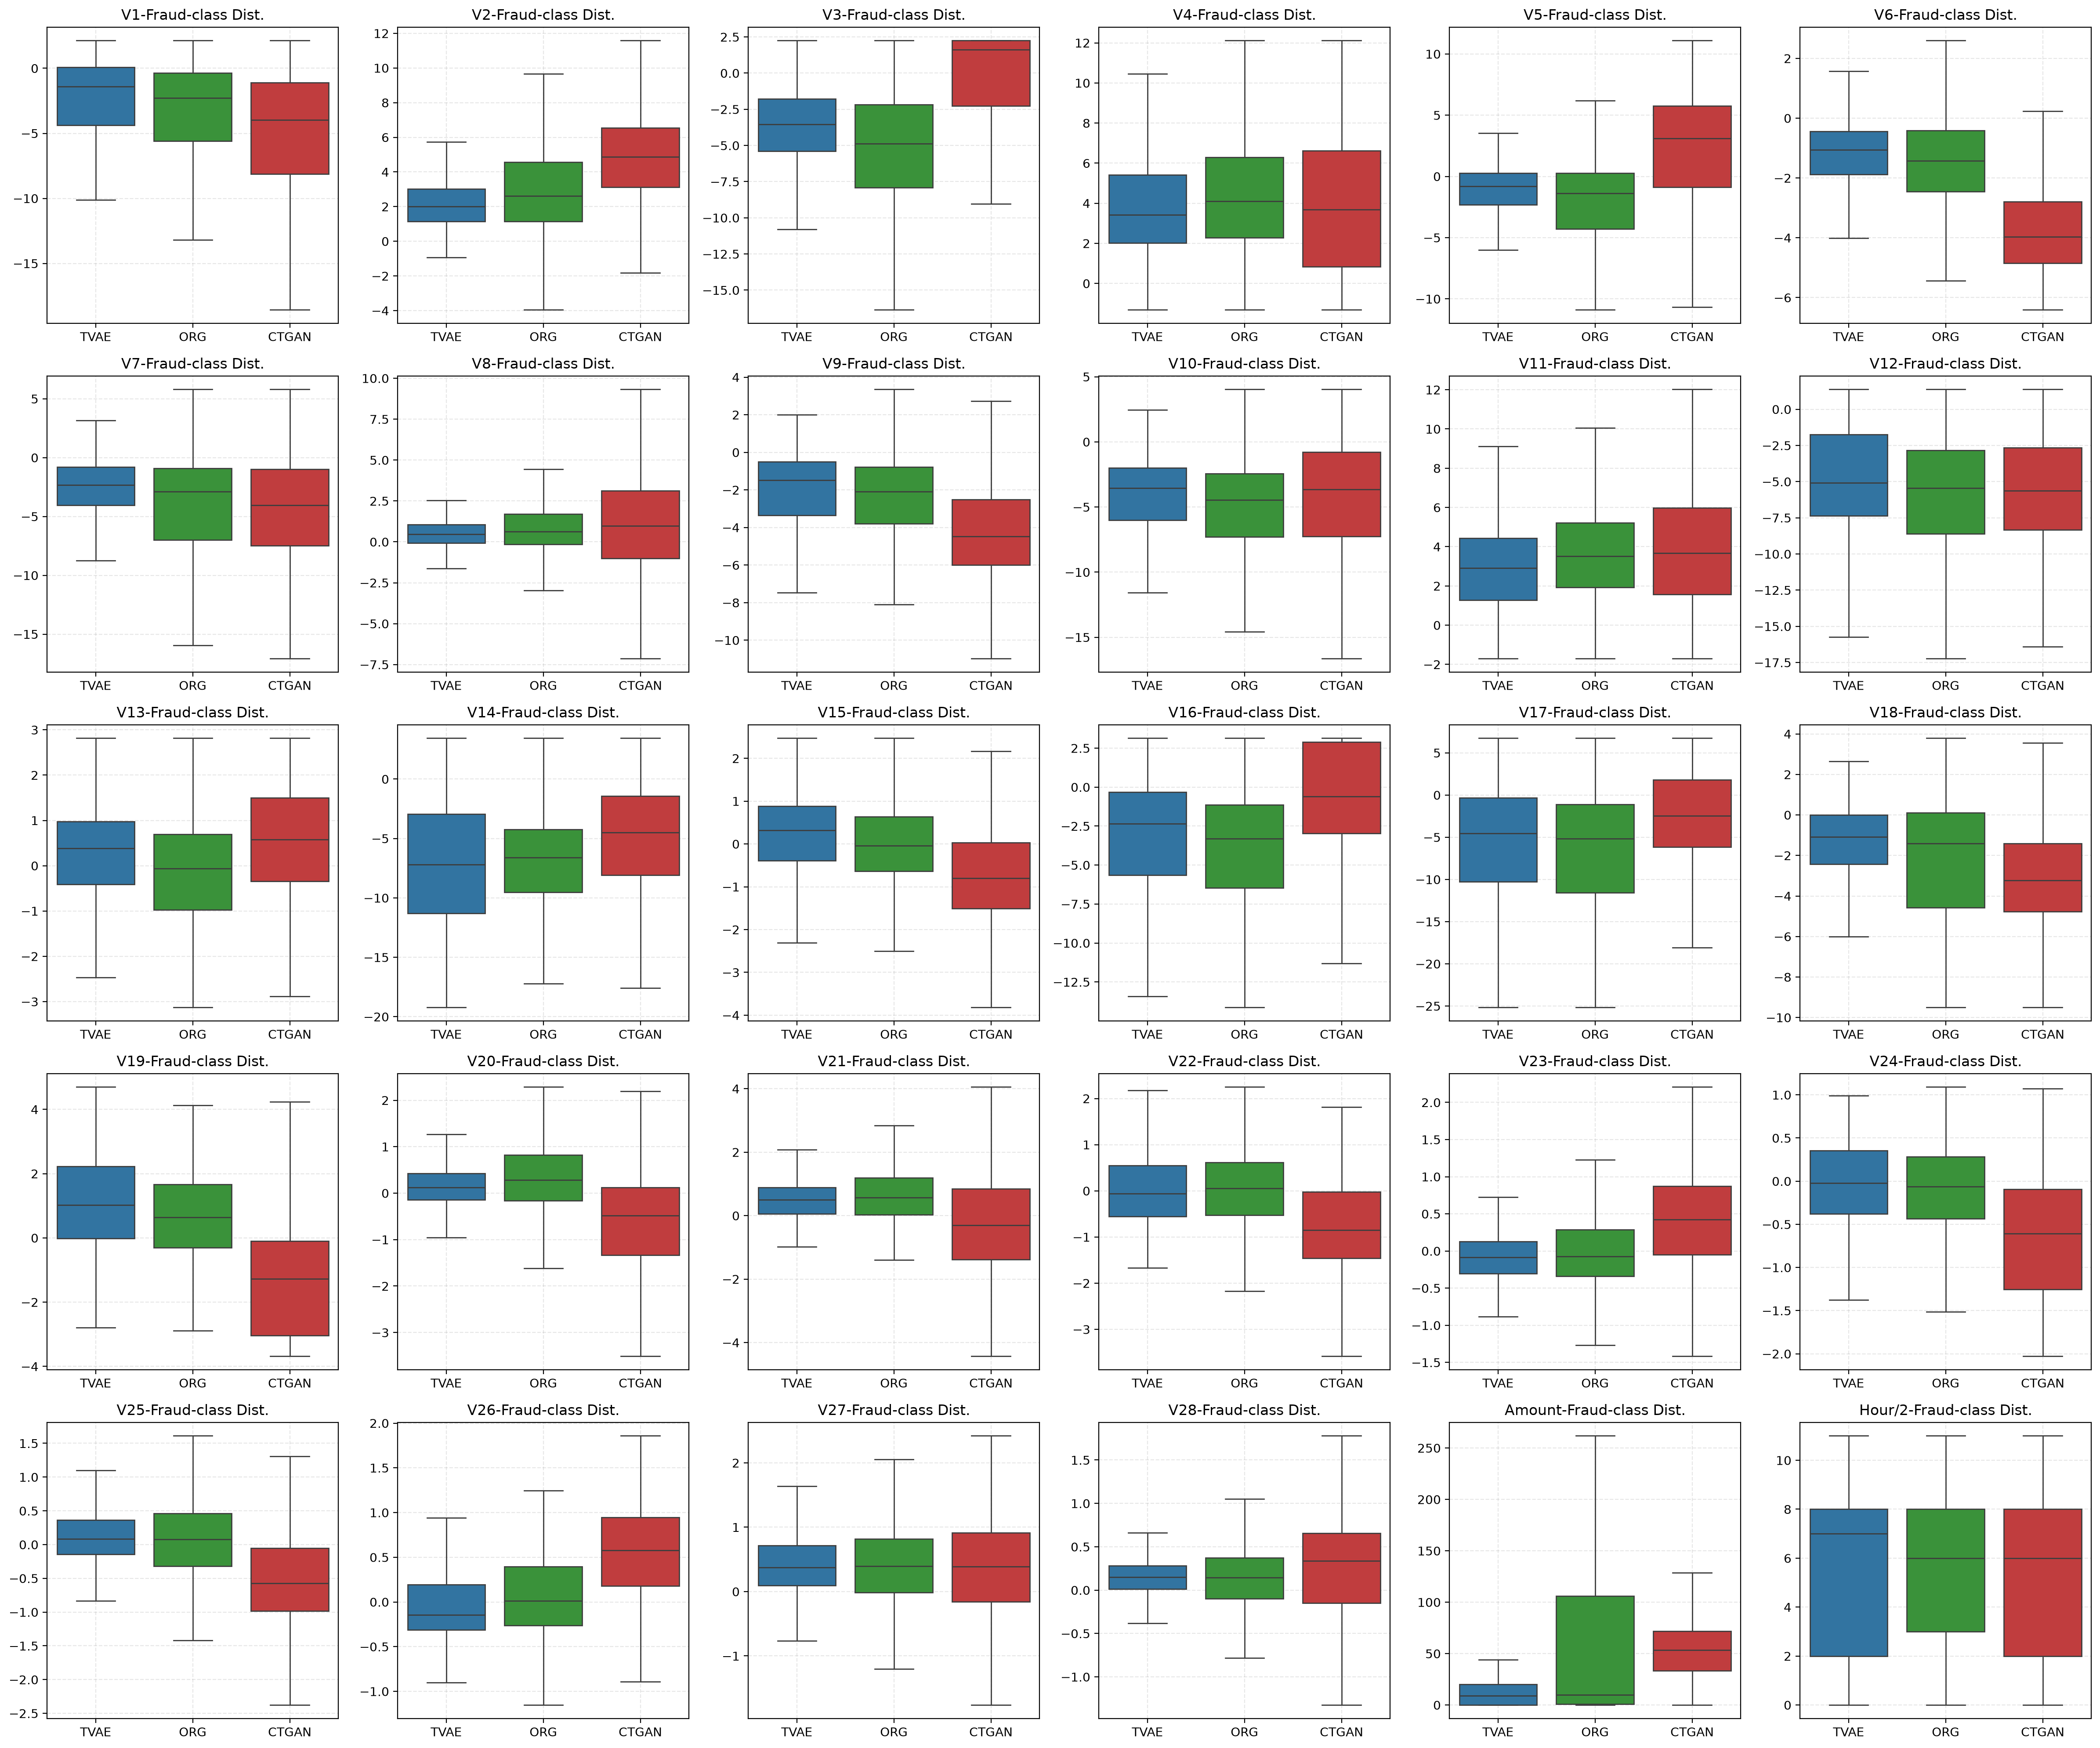

In [29]:
fig, axs = plt.subplots(m,n, figsize=(4*n,4*m))
for ax,col in zip(axs.flatten(), feat_cols):
    ut_gen.plot_dist_comparison(df, dft, dfc, col_name=col, class_label=1 , ax=ax, plot_type='box')
plt.tight_layout()

## Legit-Class Distributions

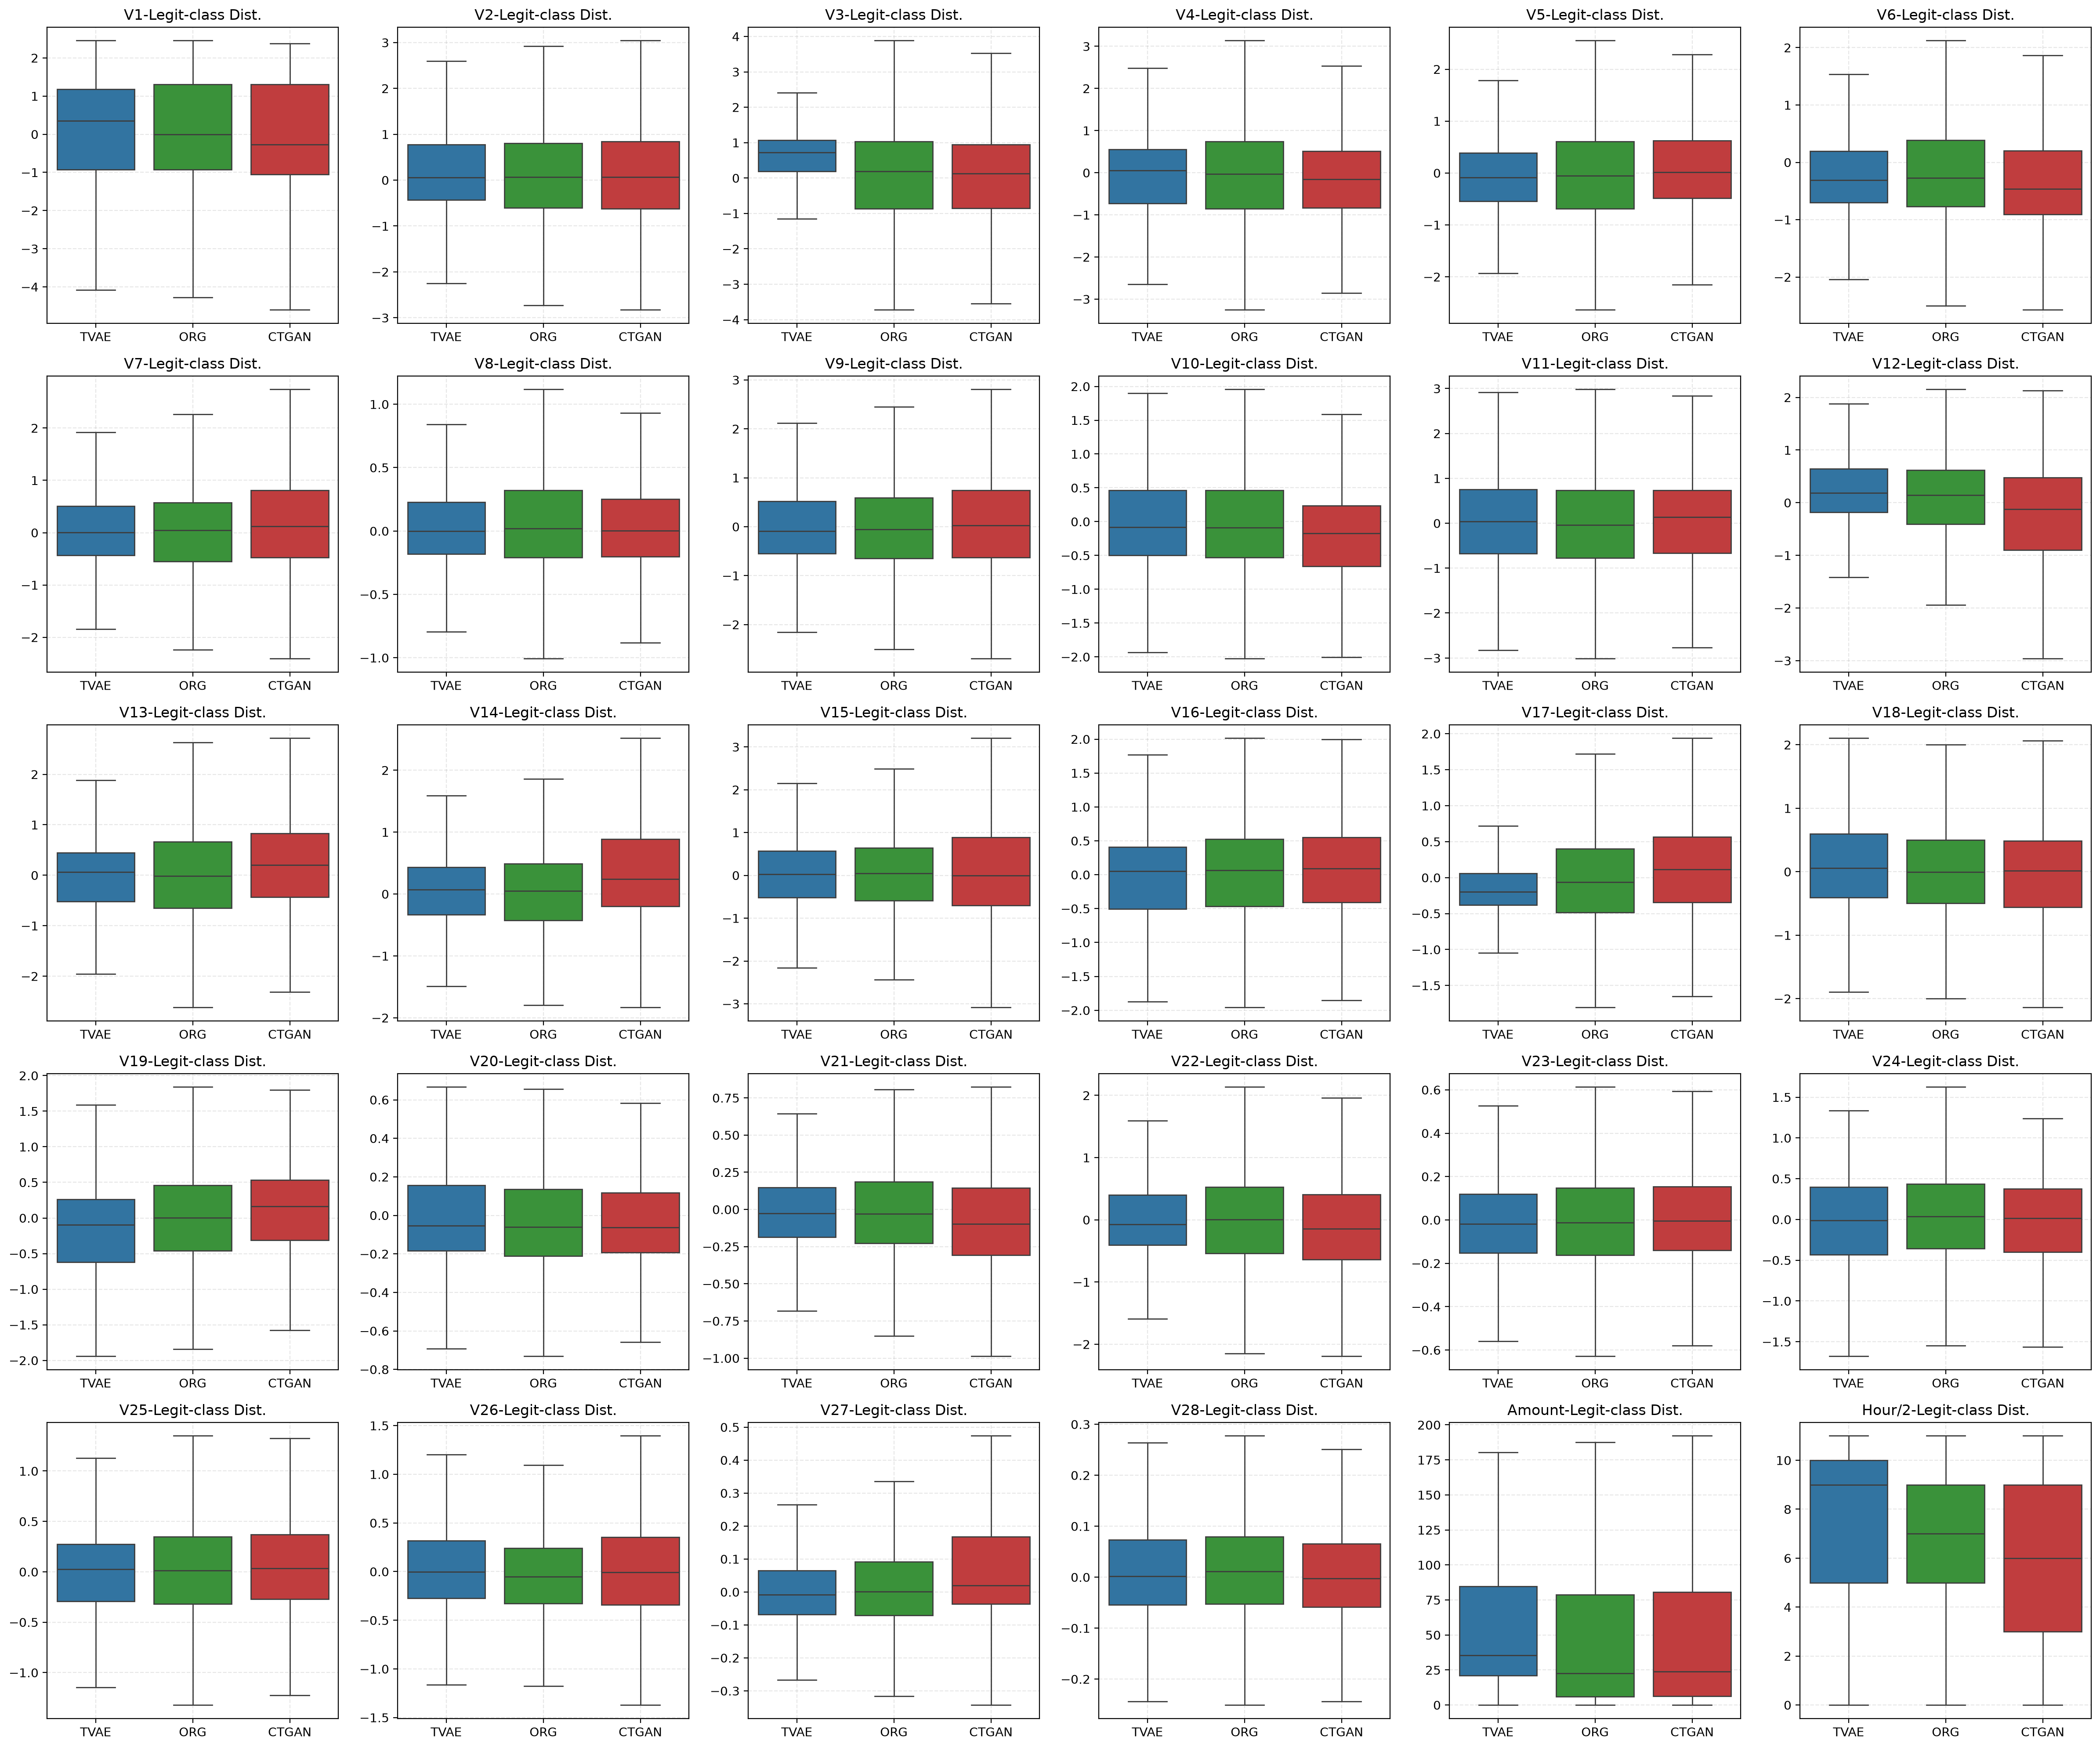

In [30]:
fig, axs = plt.subplots(m,n, figsize=(4*n,4*m))
for ax,col in zip(axs.flatten(),feat_cols):    
    ut_gen.plot_dist_comparison(df, dft, dfc, col_name=col, class_label=0 , ax=ax, plot_type='box')
plt.tight_layout()

# NOTE
- As expected due to few samples for training fraud-class, the distribution of fraud class per feature is not very promising
- The distribution of Legit-class per feature looks much better, as expected due to enough data for training

# Numerical comparison of Distribution per feature
The Quality-Report from __SDMetrics__(Synthetic data evaluation metrics) provide the following info (more info at: https://docs.sdv.dev/sdmetrics/data-metrics/quality)
- **Column Shapes:** The shape of a column describes its overall distribution. The higher the score, the more similar the distributions of real and synthetic data. (__This is our focus__)
- **Column Pair Trends:** The trend between two columns describes how they vary in relation to each other, for example the correlation. The higher the score, the more the trends are alike. (for 30 features we have 30*31/2=435 combinations)
- **Cardinality:** Does the synthetic data capture the number of connections between parent and child tables? (NOT Availabel/Defined for Single Table like our case)

## Fraud-Class Numerical Quality Report

In [31]:
class_label = 1
real = df[df['Class'] == class_label].drop(columns=['Class']).copy()
tvae = dft[dft['Class'] == class_label].drop(columns=['Class']).copy()
ctgan = dfc[dfc['Class'] == class_label].drop(columns=['Class']).copy()

metadata_dic = ut_gen.get_metadata_dic_for_quality_report(real)
tvae_overall, tvae_shapes = ut_gen.evaluate_model_quality(real, tvae, metadata_dic, "TVAE", class_label)
ctgan_overall, ctgan_shapes = ut_gen.evaluate_model_quality(real, ctgan, metadata_dic, "CTGAN", class_label)

comparison = pd.merge(tvae_shapes,ctgan_shapes,on='Column')
# Determine winning model per column
comparison['Winner'] = comparison.apply(lambda r: 'TVAE' if r['TVAE_Score'] > r['CTGAN_Score'] else 'CTGAN', axis=1)
print("Number of winner columns per TVAE/CTGAN")
print(comparison['Winner'].value_counts().to_frame().T)

=== TVAE (Fraud Class) Quality Report ===
Overall Quality Score: 87.51%

=== CTGAN (Fraud Class) Quality Report ===
Overall Quality Score: 67.27%

Number of winner columns per TVAE/CTGAN
Winner  TVAE  CTGAN
count     24      6


## Legit-Class Numerical Quality Report

In [32]:
class_label = 0
real = df[df['Class'] == class_label].drop(columns=['Class']).copy()
tvae = dft[dft['Class'] == class_label].drop(columns=['Class']).copy()
ctgan = dfc[dfc['Class'] == class_label].drop(columns=['Class']).copy()

metadata_dic = ut_gen.get_metadata_dic_for_quality_report(real)
tvae_overall, tvae_shapes = ut_gen.evaluate_model_quality(real, tvae, metadata_dic, "TVAE", class_label)
ctgan_overall, ctgan_shapes = ut_gen.evaluate_model_quality(real, ctgan, metadata_dic, "CTGAN", class_label)

comparison = pd.merge(tvae_shapes,ctgan_shapes,on='Column')
# Determine winning model per column
comparison['Winner'] = comparison.apply(lambda r: 'TVAE' if r['TVAE_Score'] > r['CTGAN_Score'] else 'CTGAN', axis=1)
print("Number of winner columns per TVAE/CTGAN")
print(comparison['Winner'].value_counts().to_frame().T)

=== TVAE (Legit Class) Quality Report ===
Overall Quality Score: 91.16%

=== CTGAN (Legit Class) Quality Report ===
Overall Quality Score: 91.62%

Number of winner columns per TVAE/CTGAN
Winner  CTGAN  TVAE
count      17    13


### NOTE:

| Class Subset | Model | Overall Quality Score | Feature Wins (out of 30) | Win Rate (%) | Winner Model |
| --- | --- | --- | --- | --- | --- |
| **Fraud (`Class = 1`)** | **TVAE** | **87.51%** | **24** | **80.0%** | **TVAE** 🏆 |
|  | CTGAN | 67.27% | 6 | 20.0% |  |
| **Legit (`Class = 0`)** | TVAE | 91.16% | 13 | 43.3% |  |
|  | **CTGAN** | **91.62%** | **17** | **56.7%** | **CTGAN** 🏆 |

---

### Key Takeaways

1. **Fraud Class Dominance (Critical):** **TVAE vastly outperforms CTGAN on the minority Fraud class** with an overall score of **87.51% vs. 67.27%** and winning 24 out of 30 columns. CTGAN struggles significantly on the minority class distribution.
2. **Legit Class Parity:** On the majority Legit class, both models perform nearly identically ($\sim 91\%$), with CTGAN holding a slight edge (17 feature wins vs. 13).
3. **Overall Recommendation:** **TVAE is the superior model for this dataset**, as capturing minority fraud distributions accurately is the primary objective of fraud data synthesis.

# Classification-metric of generated data on trained models on real data
- we have 3 dataset: df: read data, dft: generated by TVAE, and dfc: generated by CTGAN
- all have same number of fraud samples and same number of legit samples
- 50 time randomly we select `20%` of these data (use stratify by Class)
- we calculate all classification metrics by 3 models trained on real data in previous notebook
- we check the distributions of most important metrics: 'Precision', 'Recall', 'F2-Score', 'PR-AUC'
- we like to see if CTGAN or TVAE are closer to real data, and which model is better (esp between XGB_None and CTGAN)
- No optimum threshold used, just default threshold

In [33]:
from tqdm.notebook import tqdm
from sklearn.model_selection import train_test_split
palette = {'ORG': 'tab:green', 'TVAE':'tab:blue', 'CTGAN':'tab:red'}
order=['TVAE', 'ORG', 'CTGAN'] # ORG in the middle
model_list=['None', 'CTGAN', 'TVAE', 'BSMOTE', 'SMOTE']
cols=['F2-Score', 'PR-AUC', 'Recall', 'Precision']

In [34]:
metric_dic = {}
for model in tqdm(model_list,'model-count'):
    model_filename =f'XGB_{model}_model.pkl'
    clf = joblib.load(settings.MODEL_DIR/model_filename)
    print(f'Using {model_filename}')
    metrics=[]
    for j in tqdm(range(50),'Iteration'):
        for tag, dfj in zip(['ORG','TVAE','CTGAN'],[df,dft,dfc]):
            train_df, test_df = train_test_split(dfj, test_size=0.2, stratify=dfj["Class"], random_state=settings.RANDOM_SEED+j*100)
            y_test = test_df['Class']
            X_test = test_df.drop(columns=['Class'])
            metrics.append(ut.get_model_scores(X_test, y_test, tag, clf))
    metric_dic[model]=pd.DataFrame(metrics)

model-count:   0%|          | 0/5 [00:00<?, ?it/s]

Using XGB_None_model.pkl


Iteration:   0%|          | 0/50 [00:00<?, ?it/s]

Using XGB_CTGAN_model.pkl


Iteration:   0%|          | 0/50 [00:00<?, ?it/s]

...

Iteration:   0%|          | 0/50 [00:00<?, ?it/s]

Using XGB_BSMOTE_model.pkl


Iteration:   0%|          | 0/50 [00:00<?, ?it/s]

Using XGB_SMOTE_model.pkl


Iteration:   0%|          | 0/50 [00:00<?, ?it/s]

In [35]:
# Load our test benchmark result from step1
test_metrics_df=pd.read_csv(settings.IMG_DIR/'metrics.csv', index_col='Model')
test_metrics_df=test_metrics_df[test_metrics_df.Threshold == 0.5]
test_metrics_df

,Threshold,Accuracy,Precision,Recall,F1-Score,F2-Score,F3-Score,PR-AUC,ROC-AUC
Model,,,,,,,,,
XGB_None,0.5,0.999700,0.963855,0.851064,0.903955,0.871460,0.861141,0.901240,0.982037
XGB_BSMOTE,0.5,0.999648,0.911111,0.872340,0.891304,0.879828,0.876068,0.888672,0.983577
XGB_SMOTE,0.5,0.999630,0.884211,0.893617,0.888889,0.891720,0.892667,0.892660,0.987959
XGB_TVAE,0.5,0.999436,0.829787,0.829787,0.829787,0.829787,0.829787,0.870592,0.980445
XGB_CTGAN,0.5,0.999612,0.918605,0.840426,0.877778,0.854978,0.847639,0.913786,0.983319


In [36]:
#
def plot_metric_comparision(
    j:int,
    model_list:list[str] = model_list,
    cols:list[str] = cols,
    metric_dic:dict[str,pd.DataFrame] = metric_dic,
    order:list[str] =order,
    test_metrics_df:pd.DataFrame | None=None
):
    """
    quick helper to plot boxplot on selected metrics: cols=['F2-Score', 'PR-AUC', 'Recall', 'Precision']
    based on the results collected in metric_dic
    Args:
        - j: integer index refer to model in 
        - model_list: list of already trained classification models tag e.g. model_list=['None', 'CTGAN', 'TVAE', 'BSMOTE', 'SMOTE']
        - cols: list of selected metrics e.g. cols = ['F2-Score', 'PR-AUC', 'Recall', 'Precision']
        - order: order when plotting e.g. order=['TVAE', 'ORG', 'CTGAN'] # ORG in the middle
        - test_metrics_df: dataframe contains test results benchmark (if avvailable)
    """
    model_name= f'XGB_{model_list[j]}'
    fig, axs = plt.subplots(2,2,figsize=(8,6))
    for ax,col in zip(axs.flatten(), cols):
        sns.boxplot(data=metric_dic[model_list[j]], x='Model', y=col, ax=ax, palette=palette, showfliers=False, hue='Model', legend=False, order=order)
        if test_metrics_df is not None:
            ax.axhline(y=test_metrics_df.loc[model_name,col].item(),color='red', linestyle='-.', linewidth=1.5, label='Test-Benchmark')
            ax.legend()
        ax.grid()
        
    plt.suptitle(f'Using {model_name} Model')
    plt.tight_layout()

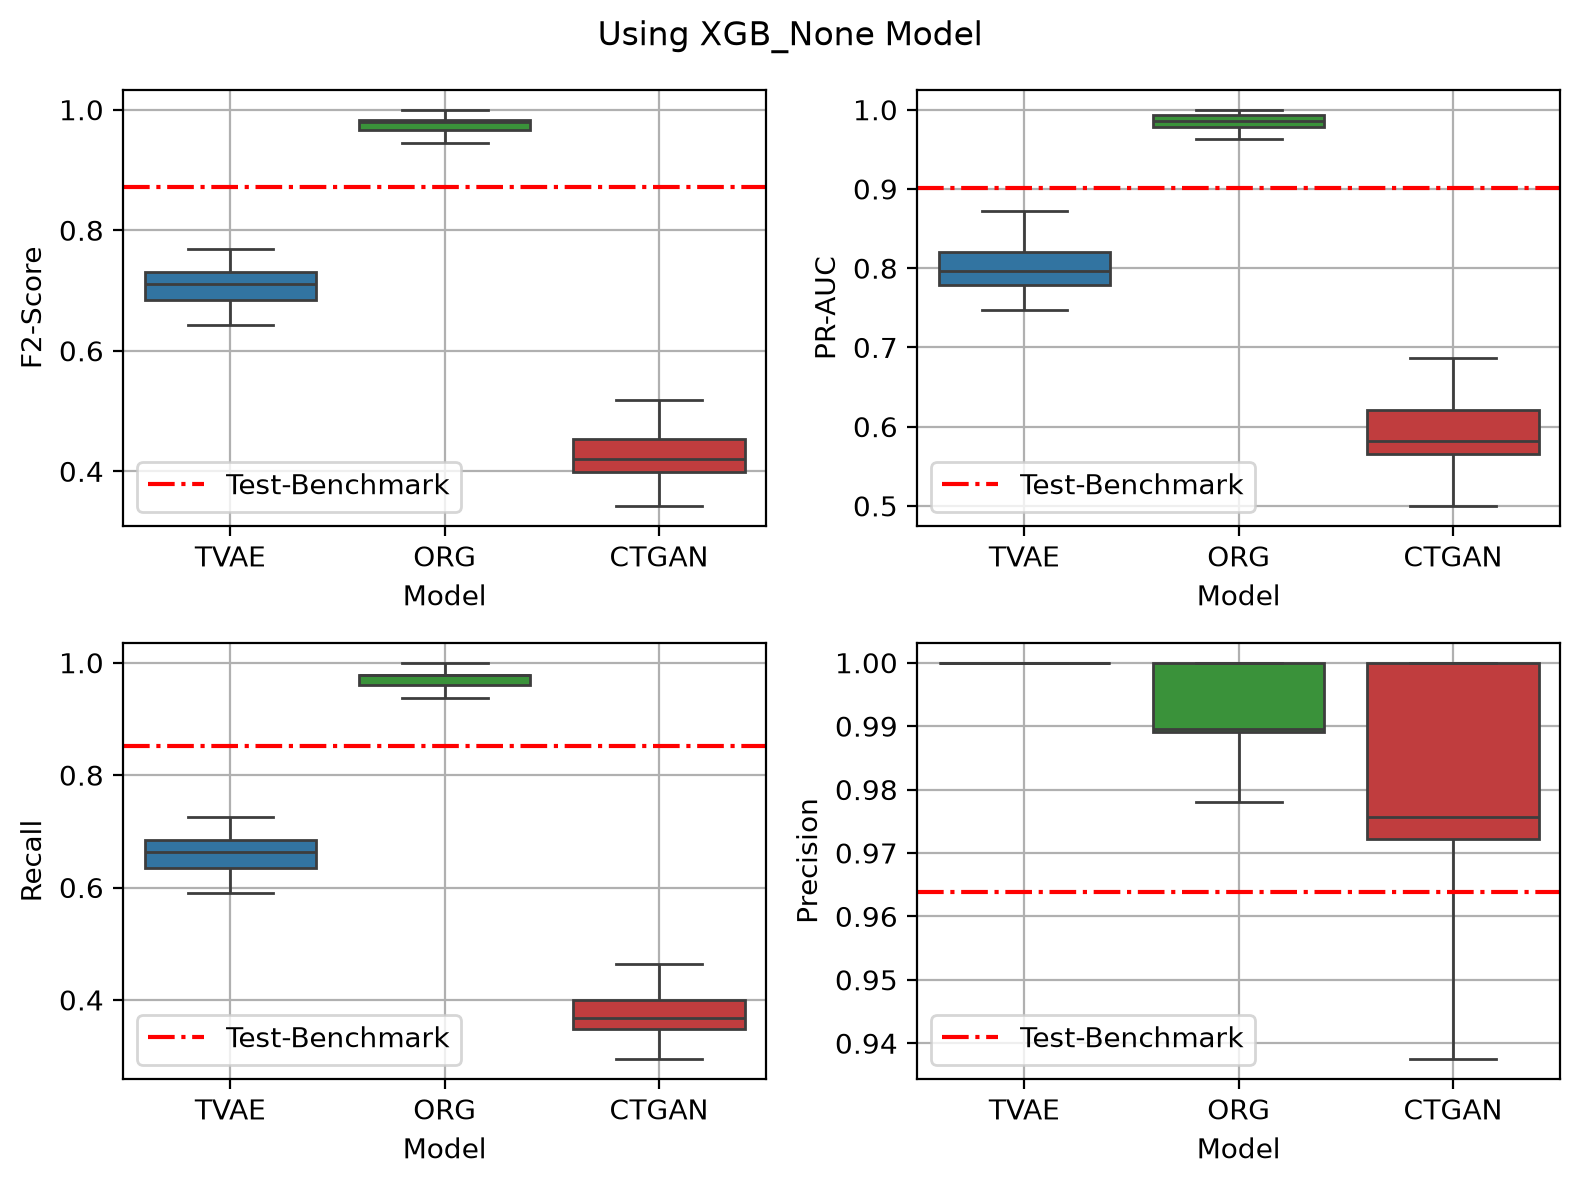

In [37]:
plot_metric_comparision(0, test_metrics_df=test_metrics_df)
plt.savefig(settings.IMG_DIR/'using_xgb_none.png', dpi=600)

### Note Using XGB_None
- on CTGAN-generated-data results in very low metrics of Recall, F2-Score, and PR-AUC
- on TVAE-generated data results in Recall and F2-Score below `80%` not promising

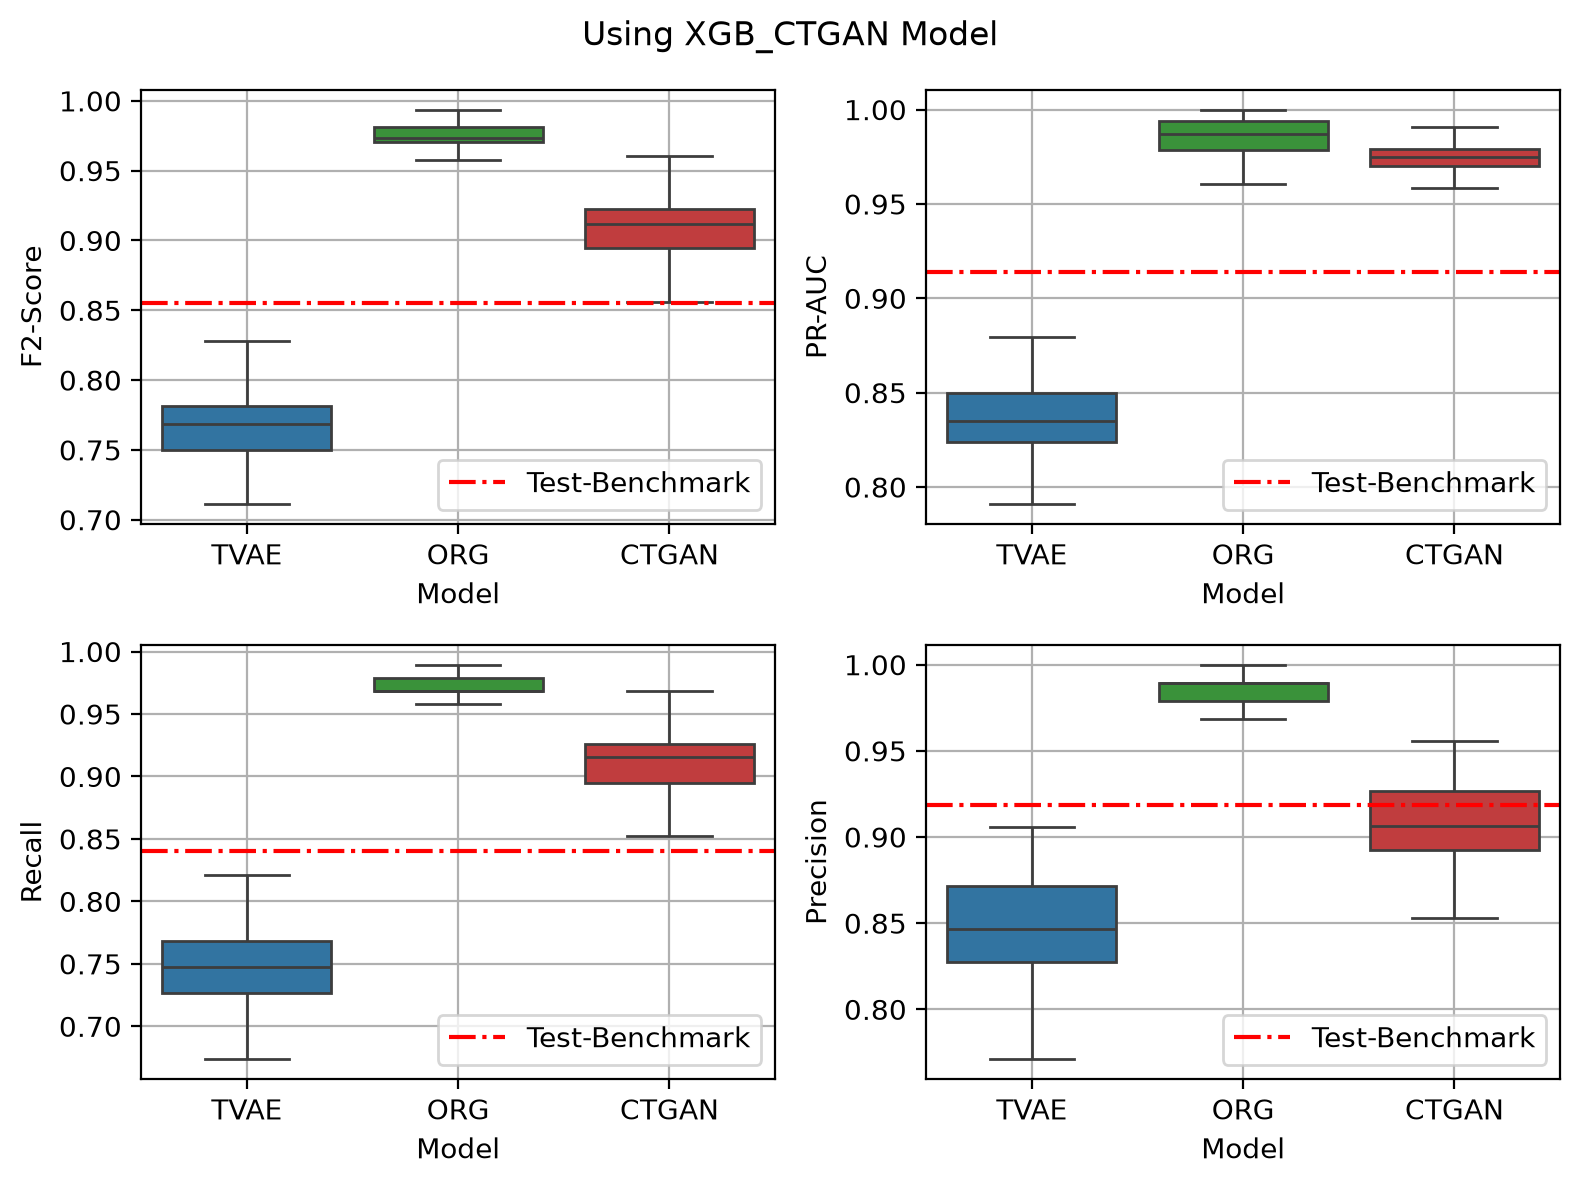

In [38]:
plot_metric_comparision(1, test_metrics_df=test_metrics_df)
plt.savefig(settings.IMG_DIR/'using_xgb_ctgan.png', dpi=600)

### Note Using XGB_CTGAN
- on CTGAN-generated-data results in close metric value to real data, and overall promising
- on TVAE-generated data results are below the results for CTGAN-generated data

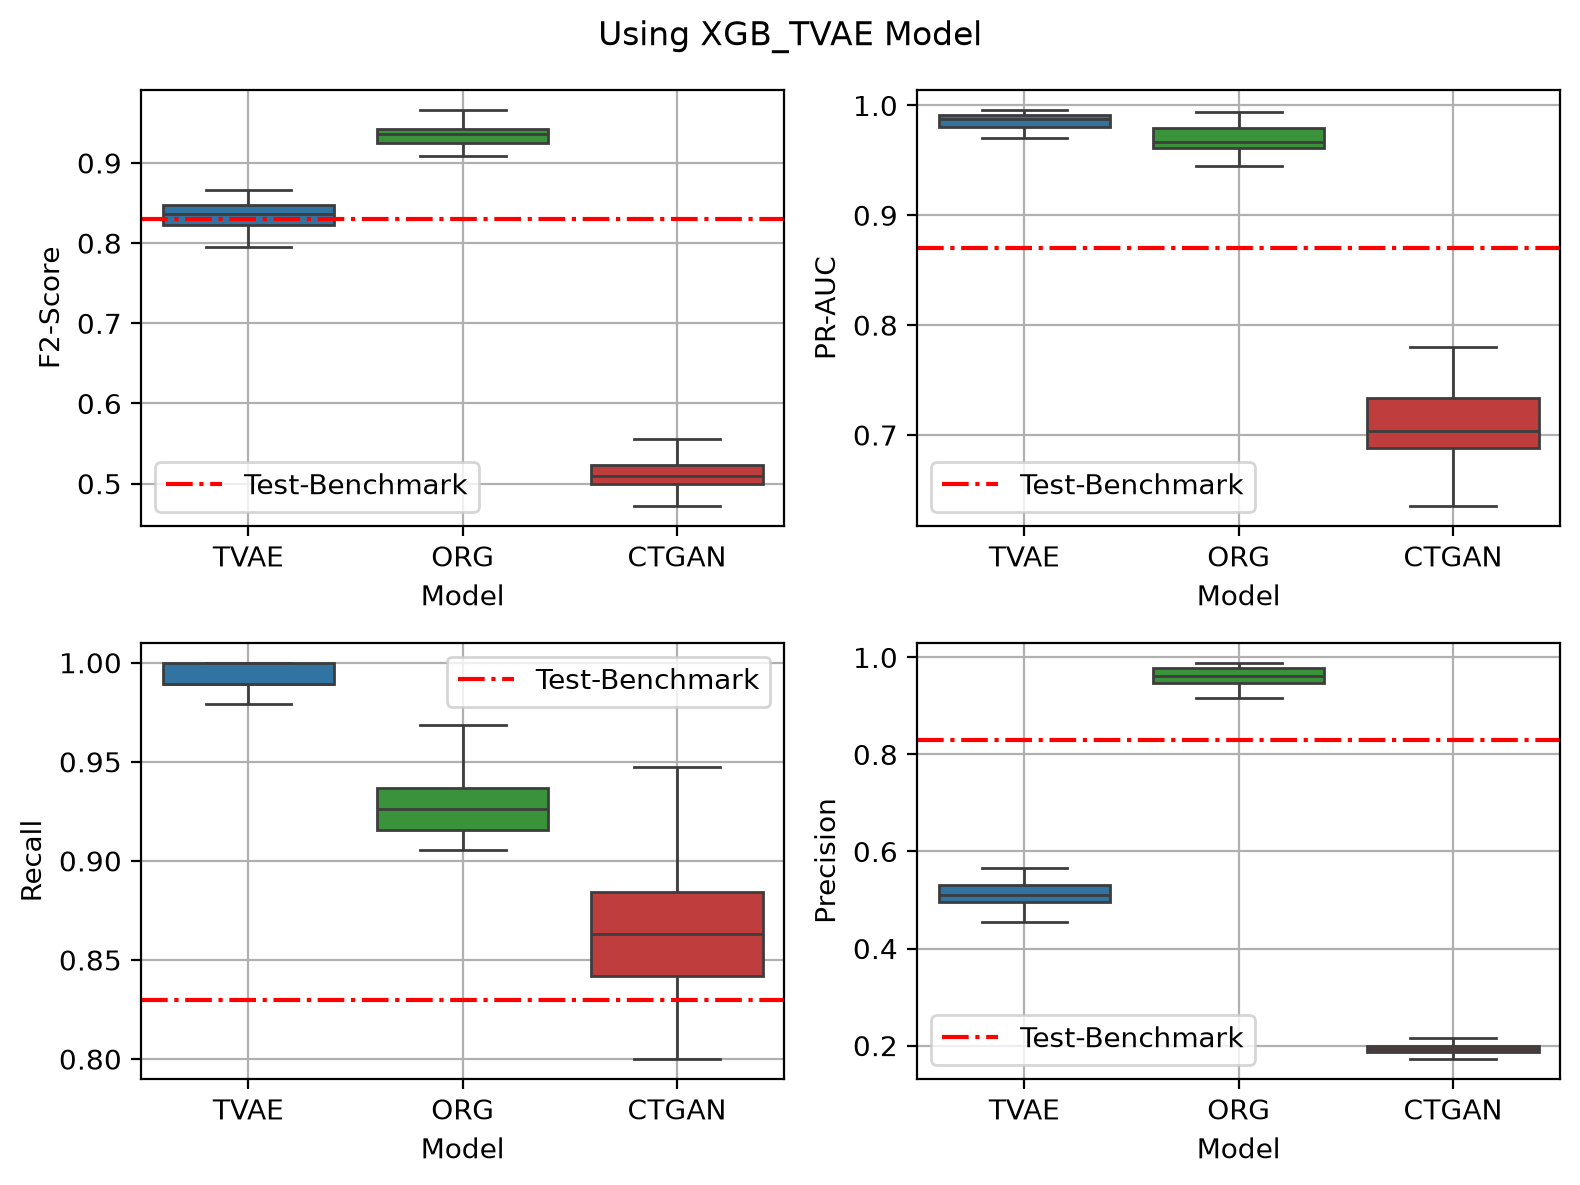

In [39]:
plot_metric_comparision(2, test_metrics_df=test_metrics_df)
plt.savefig(settings.IMG_DIR/'using_xgb_tva.png', dpi=600)

### Note Using XGB_TVAE
- on CTGAN-generated-data results in poor metric on Precision, F2-Score and PR-AUC
- on TVAE-generated data results is not acceptable with precision below `60%` in spite of having very high recall!

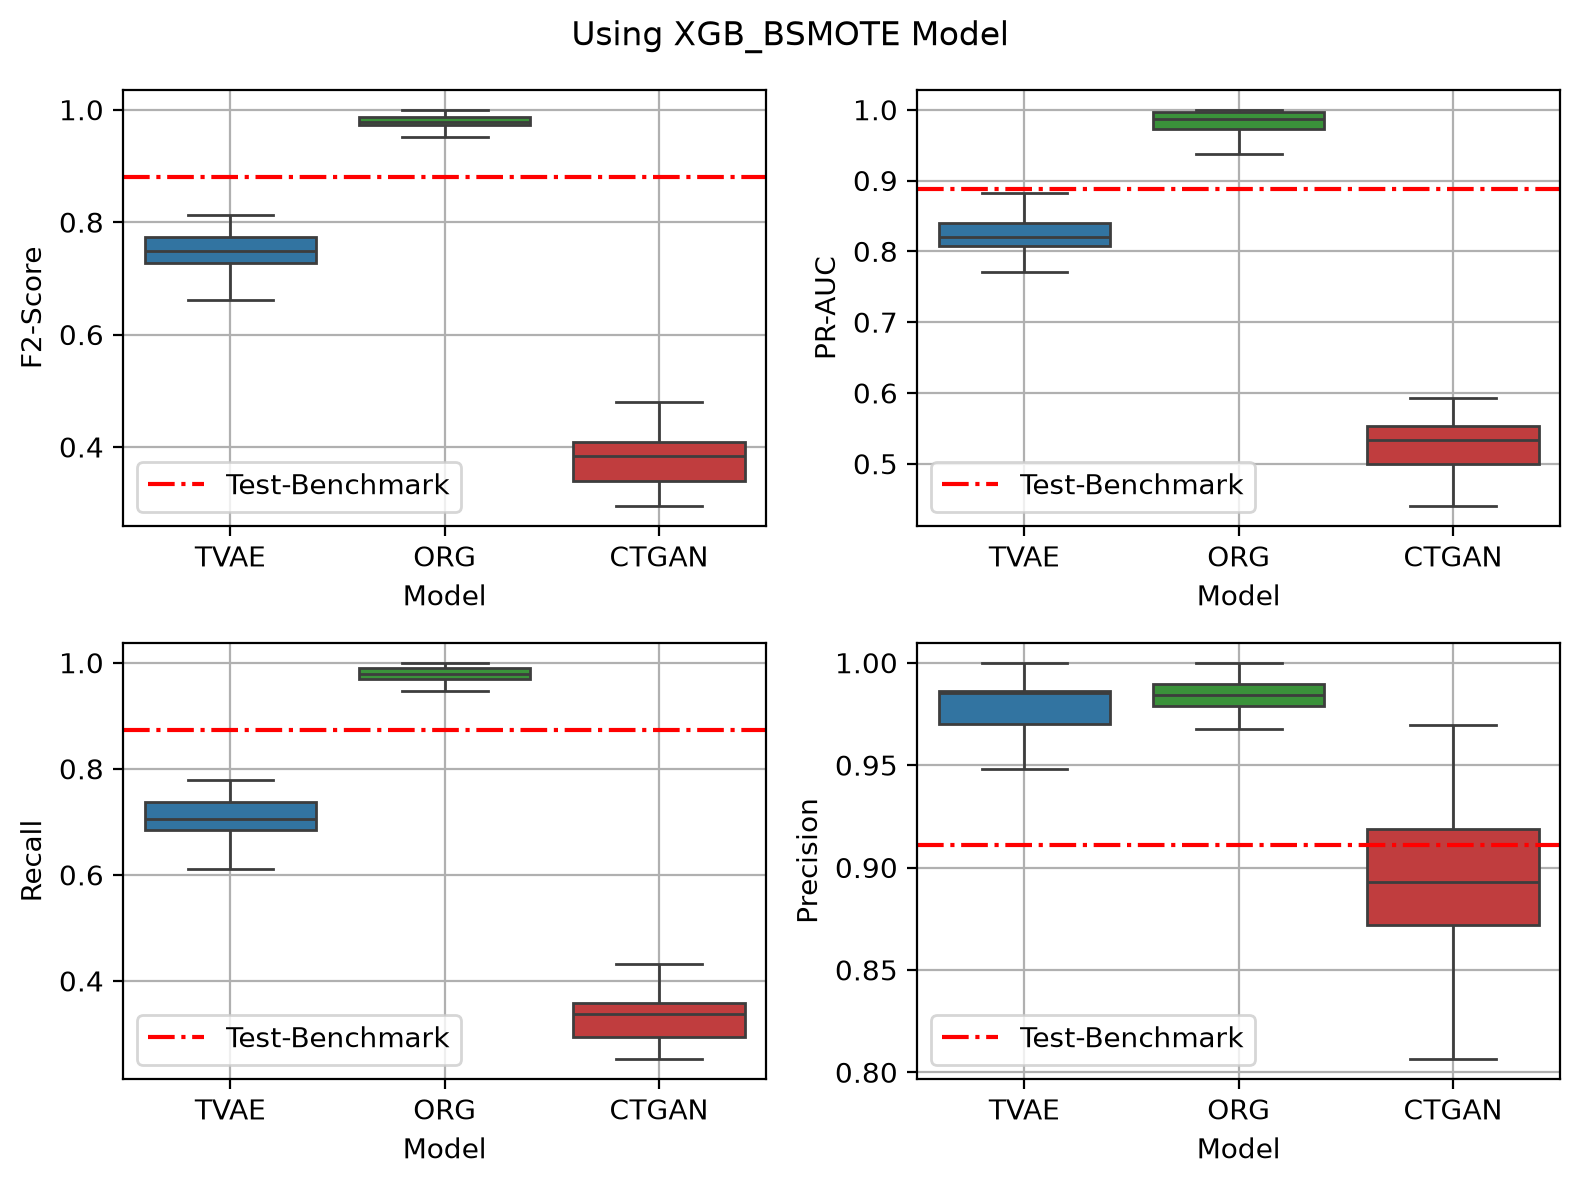

In [40]:
plot_metric_comparision(3, test_metrics_df=test_metrics_df)
plt.savefig(settings.IMG_DIR/'using_xgb_bsmote.png', dpi=600)

### Note Using XGB_BSMOTE
- on CTGAN-generated-data results in poor metric on Precision, F2-Score and PR-AUC
- on TVAE-generated data results is marginal for F2-Score (below `80%`)

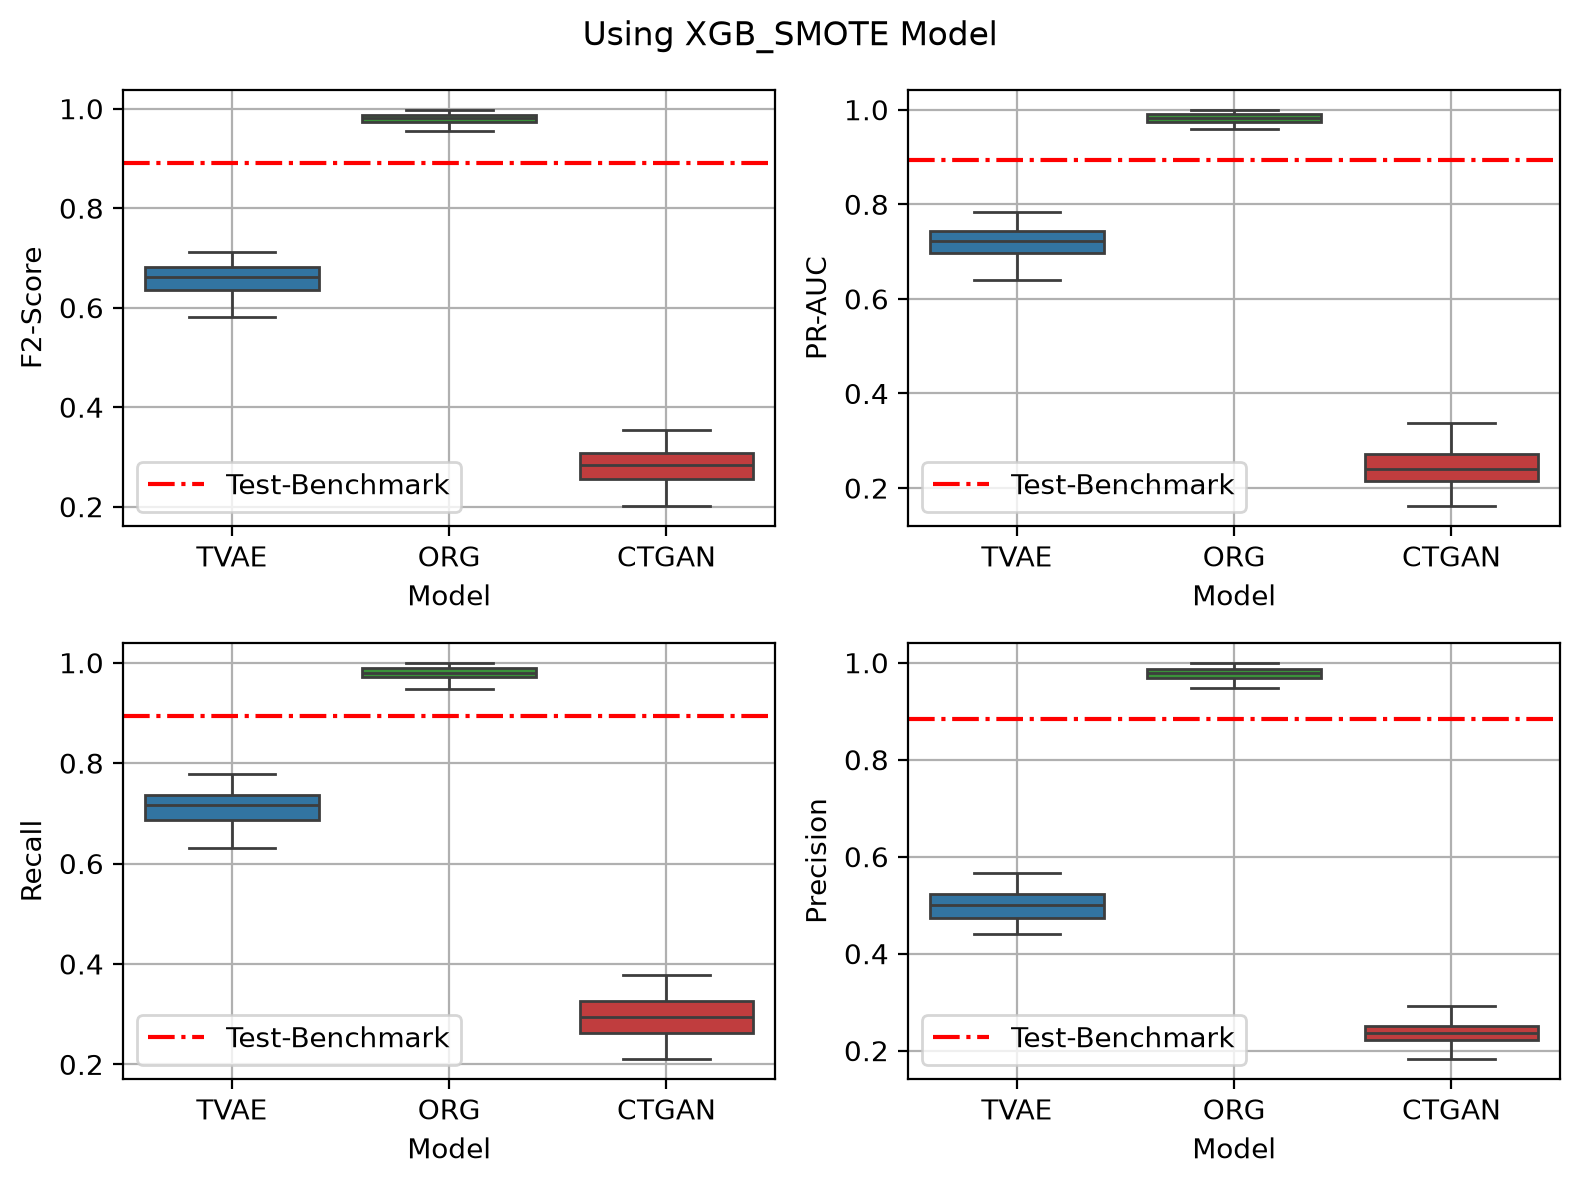

In [41]:
plot_metric_comparision(4, test_metrics_df=test_metrics_df)
plt.savefig(settings.IMG_DIR/'using_xgb_smote.png', dpi=600)

### Note Using XGB_SMOTE
- on CTGAN-generated-data results in poor metric on Precision, F2-Score and PR-AUC, and Recall
- on TVAE-generated data results in Precision, F2-Score and PR-AUC, and Recall

In [42]:
df_all_list=[]
for model in model_list:
    dftmp=metric_dic[model].copy()
    dftmp=dftmp.groupby('Model', as_index=False).mean()
    dftmp['Model']= dftmp['Model']+f'-XGB_{model}'
    df_all_list.append(dftmp)
df_all_mean = pd.concat(df_all_list)

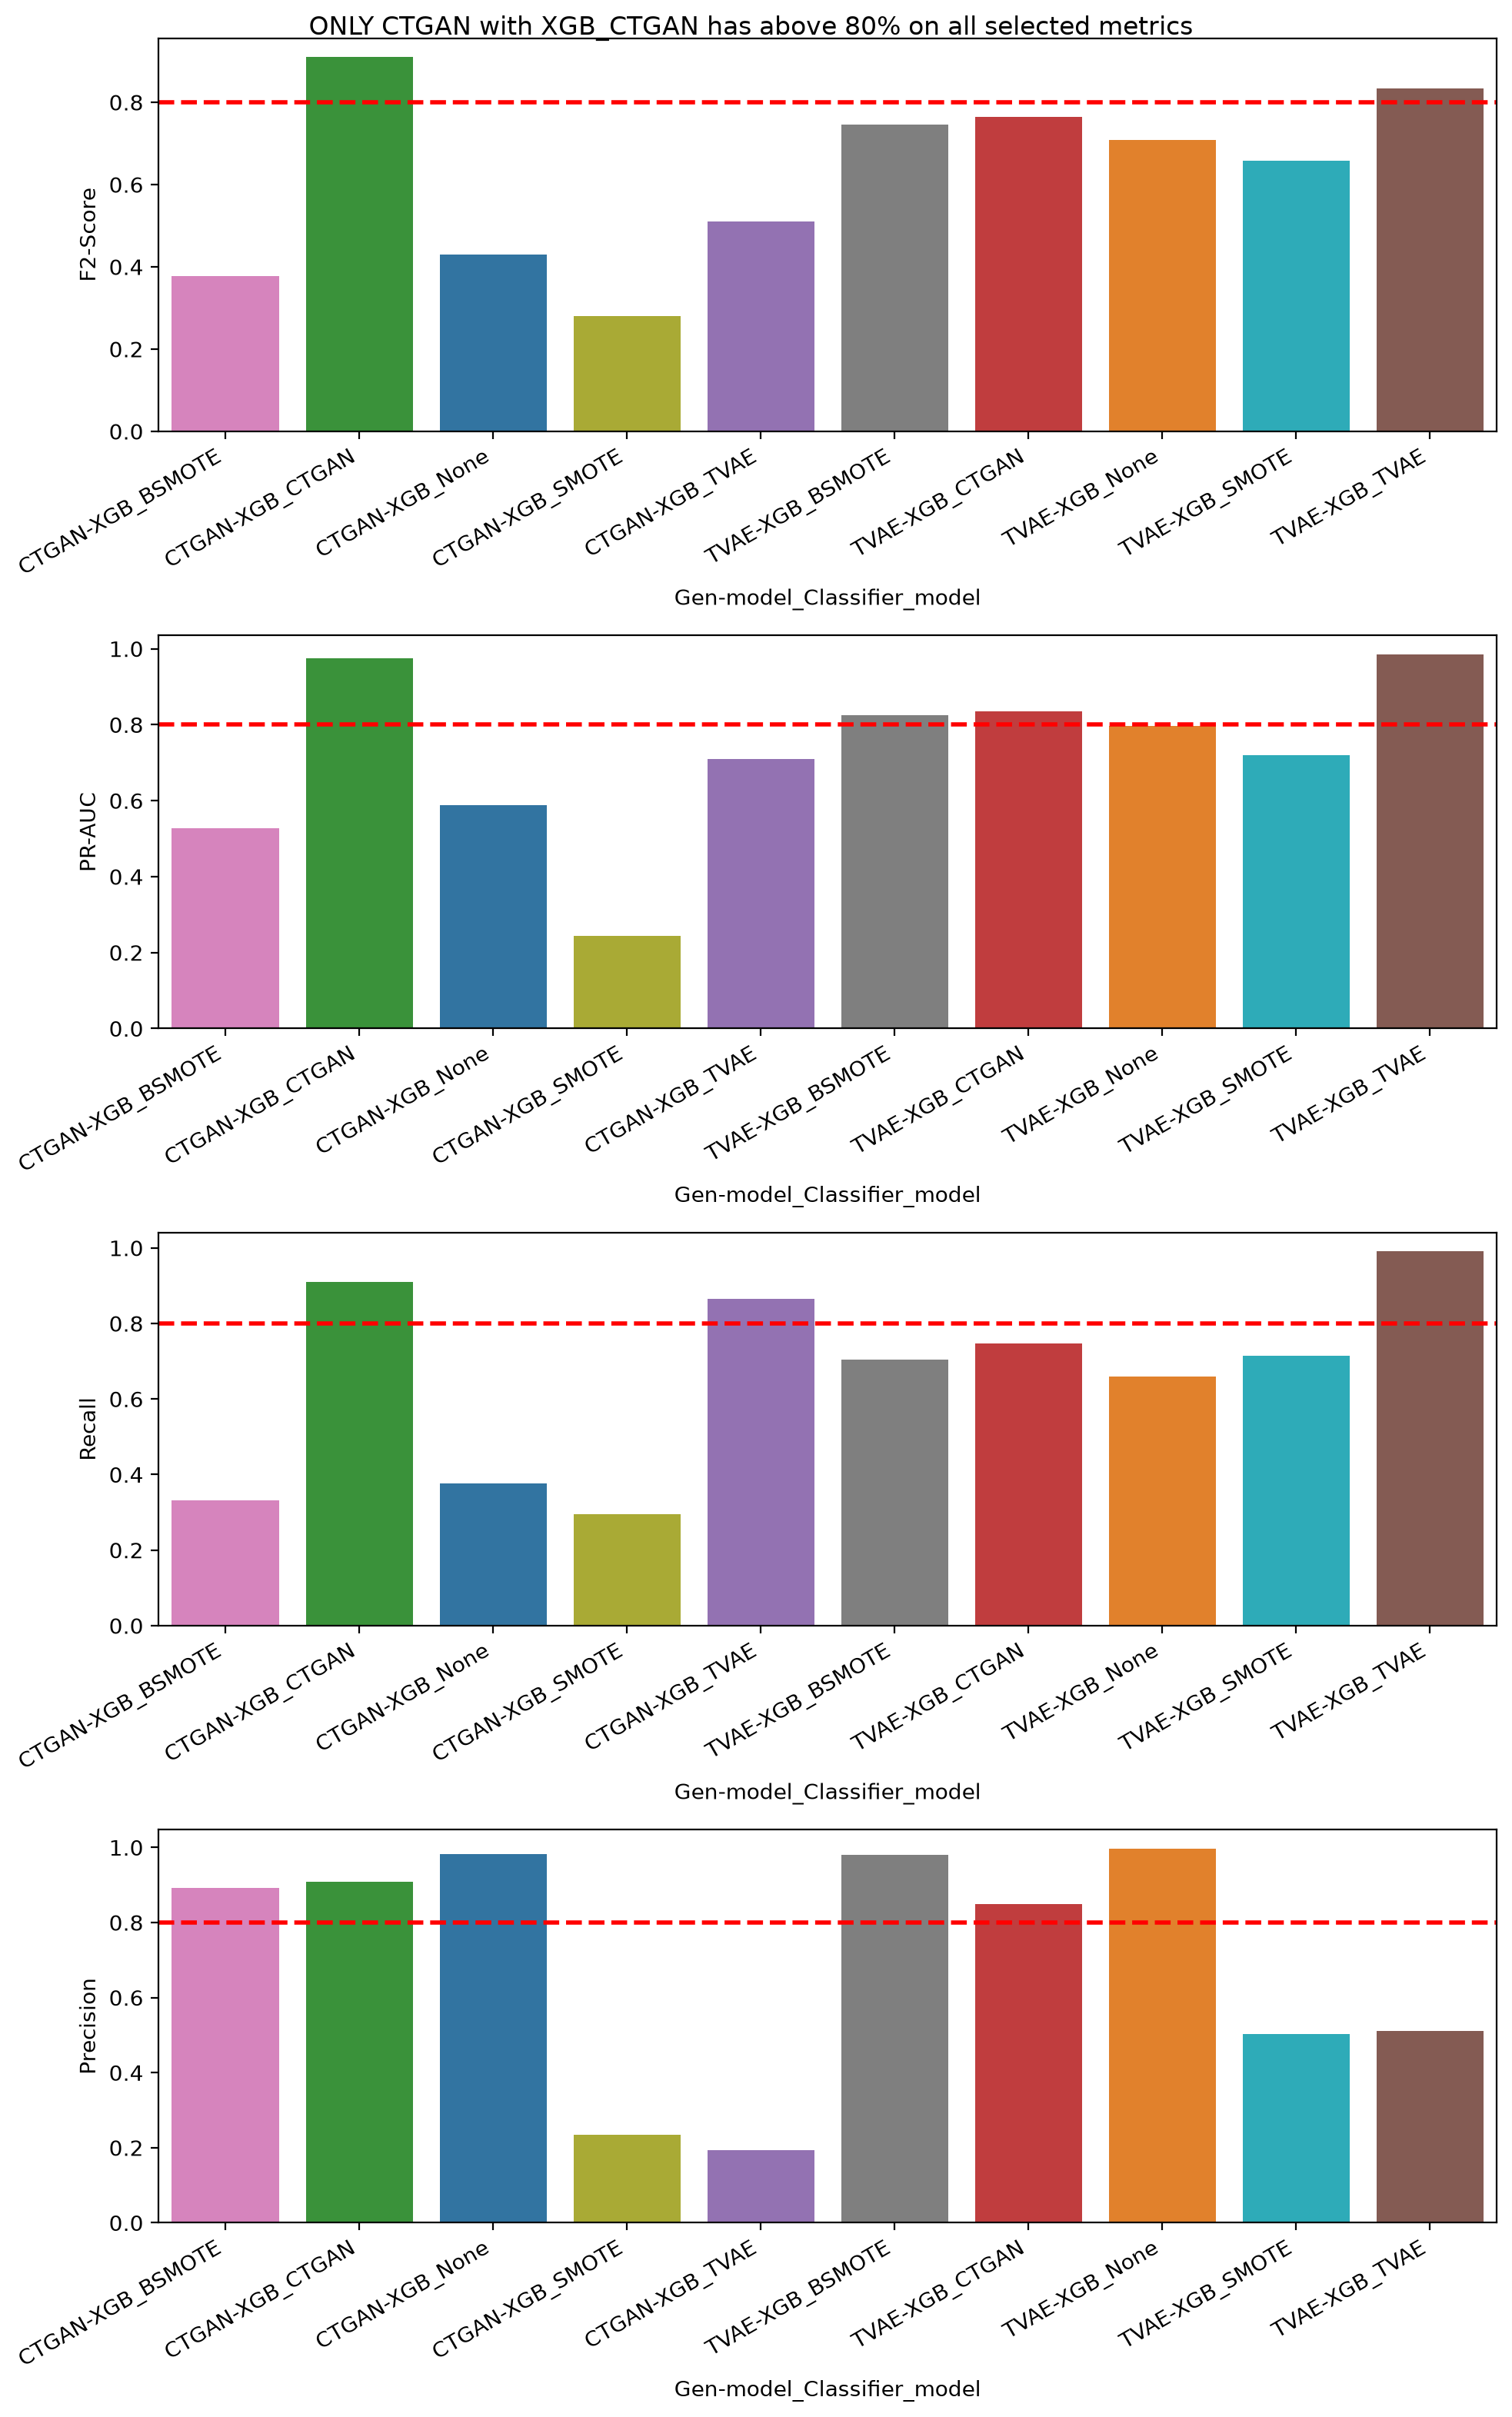

In [43]:
# Keep rows where the Model column does NOT start with 'ORG'
df_all_mean_no_org = df_all_mean[~df_all_mean['Model'].str.startswith('ORG')].reset_index(drop=True).copy()
order = sorted(df_all_mean_no_org.Model.unique().tolist())
fig, axs = plt.subplots(4,1,figsize=(10,16))
for ax,col in zip(axs.flatten(), cols):
    sns.barplot(data=df_all_mean_no_org, x='Model', y=col, ax=ax, hue='Model', legend=False, order=order)
    ax.axhline(y=0.8,color='red', linestyle='--', linewidth=2, label='Threshold (0.8)')
    ax.set_xlabel('Gen-model_Classifier_model')
    ax.xaxis.set_tick_params(rotation=30)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
plt.suptitle(f'ONLY CTGAN with XGB_CTGAN has above 80% on all selected metrics')
plt.tight_layout()
plt.savefig(settings.IMG_DIR/'select_gen_model_clf_model_pair.png', dpi=600)

### NOTE
As shown above the only (Generative-Model, Classification-Model) pair that satisfies at least `80%` on selected metric is CTGAN-XGB_CTGAN

# What if we build a classifier on generated data and test it on real data ?
- Who is the winner

In [44]:
clf_dic={}
clf_metrics=[]

In [45]:
N=1000
dft0g = ut_gen.get_sample_form_synthesizer(model_dic['TVAE0'], num_rows=N, feature_cols=feature_cols, class_label=0, synthesizer='tvae', ext=extF)
dft1g = ut_gen.get_sample_form_synthesizer(model_dic['TVAE1'], num_rows=N, feature_cols=feature_cols, class_label=1, synthesizer='tvae', ext=extF)
dftg=pd.concat([dft0g,dft1g])

Loading TVAE Scaler for majority-Class from /home/max/x/zc07-ml-genai-agentic/data/ml_models/tvae_majority_scaler_F.pkl
Start Generating 1000 samples ...
Loading TVAE Scaler for minority-Class from /home/max/x/zc07-ml-genai-agentic/data/ml_models/tvae_minority_scaler_F.pkl
Start Generating 1000 samples ...


In [46]:
train_df, test_df = train_test_split(dftg, test_size=0.2, stratify=dftg["Class"], random_state=settings.RANDOM_SEED)
y_train = train_df['Class']
X_train = train_df.drop(columns=['Class'])
y_test = test_df['Class']
X_test = test_df.drop(columns=['Class'])
L = len(dftg)
print(f'X-train: {len(X_train)}({len(X_train)/L:.2%}), X-test: {len(X_test)}({len(X_test)/L:.2%})')
print(f'y-train: {len(y_train)}({len(y_train)/L:.2%}), y-test: {len(y_test)}({len(y_test)/L:.2%})')

X-train: 1600(80.00%), X-test: 400(20.00%)
y-train: 1600(80.00%), y-test: 400(20.00%)


In [47]:
tag='XGB_TVAE_GEN'
clf_dic[tag], clf_metrics=ut.train_eval(X_train, y_train, X_test, y_test, tag, clf_metrics)
display(pd.DataFrame(clf_metrics).tail(2))

XGB_TVAE_GEN-Model saved at /home/max/x/zc07-ml-genai-agentic/data/ml_models/XGB_TVAE_GEN_model.pkl


,Model,Threshold,Accuracy,Precision,Recall,F1-Score,F2-Score,F3-Score,PR-AUC,ROC-AUC
0,XGB_TVAE_GEN,0.1,0.9975,0.995025,1.00,0.997506,0.999001,0.999500,0.999975,0.999975
1,XGB_TVAE_GEN,0.5,0.9950,1.000000,0.99,0.994975,0.991984,0.990991,0.999975,0.999975


In [48]:
dfc0g = ut_gen.get_sample_form_synthesizer(model_dic['CTGAN0'], num_rows=N, feature_cols=feature_cols, class_label=0, synthesizer='ctgan', ext=extF)
dfc1g = ut_gen.get_sample_form_synthesizer(model_dic['CTGAN1'], num_rows=N, feature_cols=feature_cols, class_label=1, synthesizer='ctgan', ext=extF)
dfcg=pd.concat([dfc0g,dfc1g])

Loading CTGAN Scaler for majority-Class from /home/max/x/zc07-ml-genai-agentic/data/ml_models/ctgan_majority_scaler_F.pkl
Start Generating 1000 samples ...
Loading CTGAN Scaler for minority-Class from /home/max/x/zc07-ml-genai-agentic/data/ml_models/ctgan_minority_scaler_F.pkl
Start Generating 1000 samples ...


In [49]:
train_df, test_df = train_test_split(dfcg, test_size=0.2, stratify=dfcg["Class"], random_state=settings.RANDOM_SEED)
y_train = train_df['Class']
X_train = train_df.drop(columns=['Class'])
y_test = test_df['Class']
X_test = test_df.drop(columns=['Class'])
L = len(dfcg)
print(f'X-train: {len(X_train)}({len(X_train)/L:.2%}), X-test: {len(X_test)}({len(X_test)/L:.2%})')
print(f'y-train: {len(y_train)}({len(y_train)/L:.2%}), y-test: {len(y_test)}({len(y_test)/L:.2%})')

X-train: 1600(80.00%), X-test: 400(20.00%)
y-train: 1600(80.00%), y-test: 400(20.00%)


In [50]:
tag='XGB_CTGAN_GEN'
clf_dic[tag], clf_metrics=ut.train_eval(X_train, y_train, X_test, y_test, tag, clf_metrics)
display(pd.DataFrame(clf_metrics).tail(2))

XGB_CTGAN_GEN-Model saved at /home/max/x/zc07-ml-genai-agentic/data/ml_models/XGB_CTGAN_GEN_model.pkl


,Model,Threshold,Accuracy,Precision,Recall,F1-Score,F2-Score,F3-Score,PR-AUC,ROC-AUC
2,XGB_CTGAN_GEN,0.184211,1.000,1.0,1.00,1.000000,1.000000,1.000000,1.0,1.0
3,XGB_CTGAN_GEN,0.500000,0.995,1.0,0.99,0.994975,0.991984,0.990991,1.0,1.0


In [51]:
model_list2=['TVAE_GEN','CTGAN_GEN']
order2=['TVAE', 'ORG', 'CTGAN'] 
metric_dic2 = {}
for model in tqdm(model_list2,'model-count'):
    model_filename =f'XGB_{model}_model.pkl'
    clf = joblib.load(settings.MODEL_DIR/model_filename)
    print(f'Using {model_filename}')
    metrics=[]
    for j in tqdm(range(50),'Iteration'):
        for tag, dfj in zip(['ORG','TVAE','CTGAN'],[df,dft,dfc]):
            train_df, test_df = train_test_split(dfj, test_size=0.2, stratify=dfj["Class"], random_state=settings.RANDOM_SEED+j*100)
            y_test = test_df['Class']
            X_test = test_df.drop(columns=['Class'])
            metrics.append(ut.get_model_scores(X_test, y_test, tag, clf))
    metric_dic2[model]=pd.DataFrame(metrics)

model-count:   0%|          | 0/2 [00:00<?, ?it/s]

Using XGB_TVAE_GEN_model.pkl


Iteration:   0%|          | 0/50 [00:00<?, ?it/s]

Using XGB_CTGAN_GEN_model.pkl


Iteration:   0%|          | 0/50 [00:00<?, ?it/s]

In [52]:
test_metrics_df2=pd.DataFrame(clf_metrics)
test_metrics_df2=test_metrics_df2[test_metrics_df2.Threshold == 0.5]
test_metrics_df2.set_index('Model', inplace=True)
test_metrics_df2

,Threshold,Accuracy,Precision,Recall,F1-Score,F2-Score,F3-Score,PR-AUC,ROC-AUC
Model,,,,,,,,,
XGB_TVAE_GEN,0.5,0.995,1.0,0.99,0.994975,0.991984,0.990991,0.999975,0.999975
XGB_CTGAN_GEN,0.5,0.995,1.0,0.99,0.994975,0.991984,0.990991,1.000000,1.000000


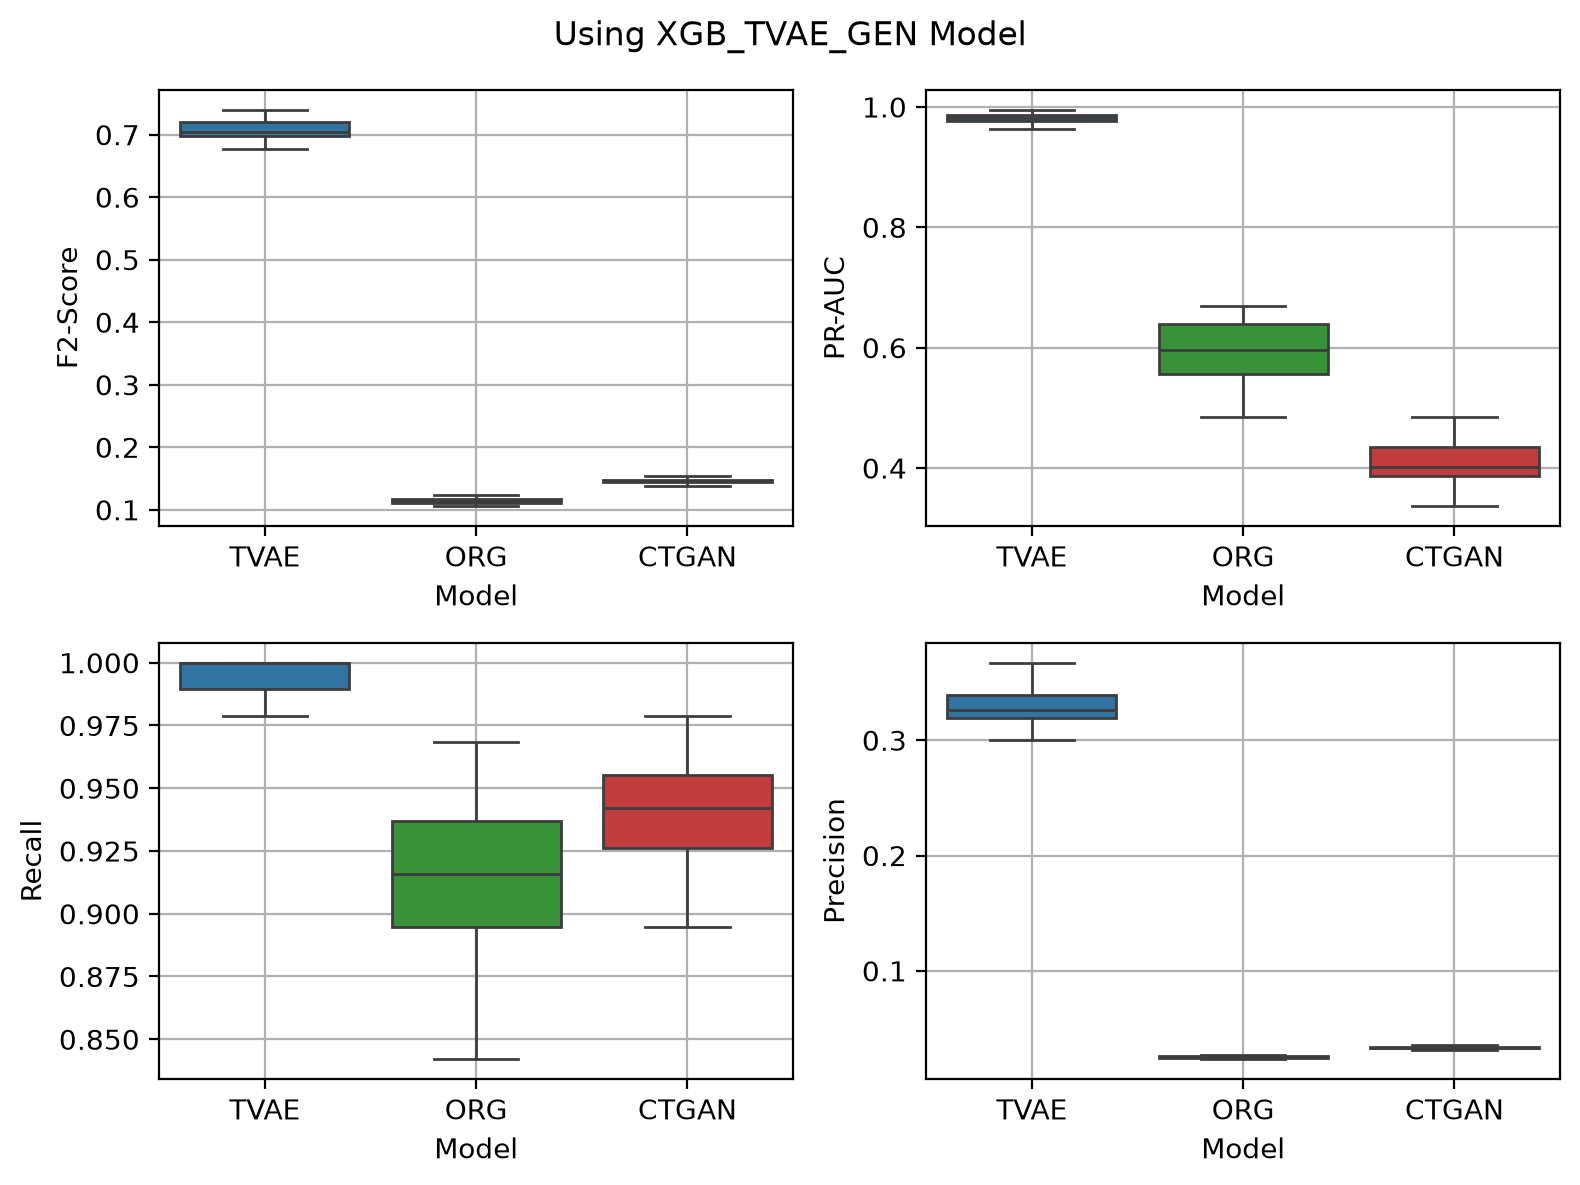

In [53]:
plot_metric_comparision(0,  model_list= model_list2,cols=cols, metric_dic = metric_dic2, order =order2) #, test_metrics_df=test_metrics_df2)

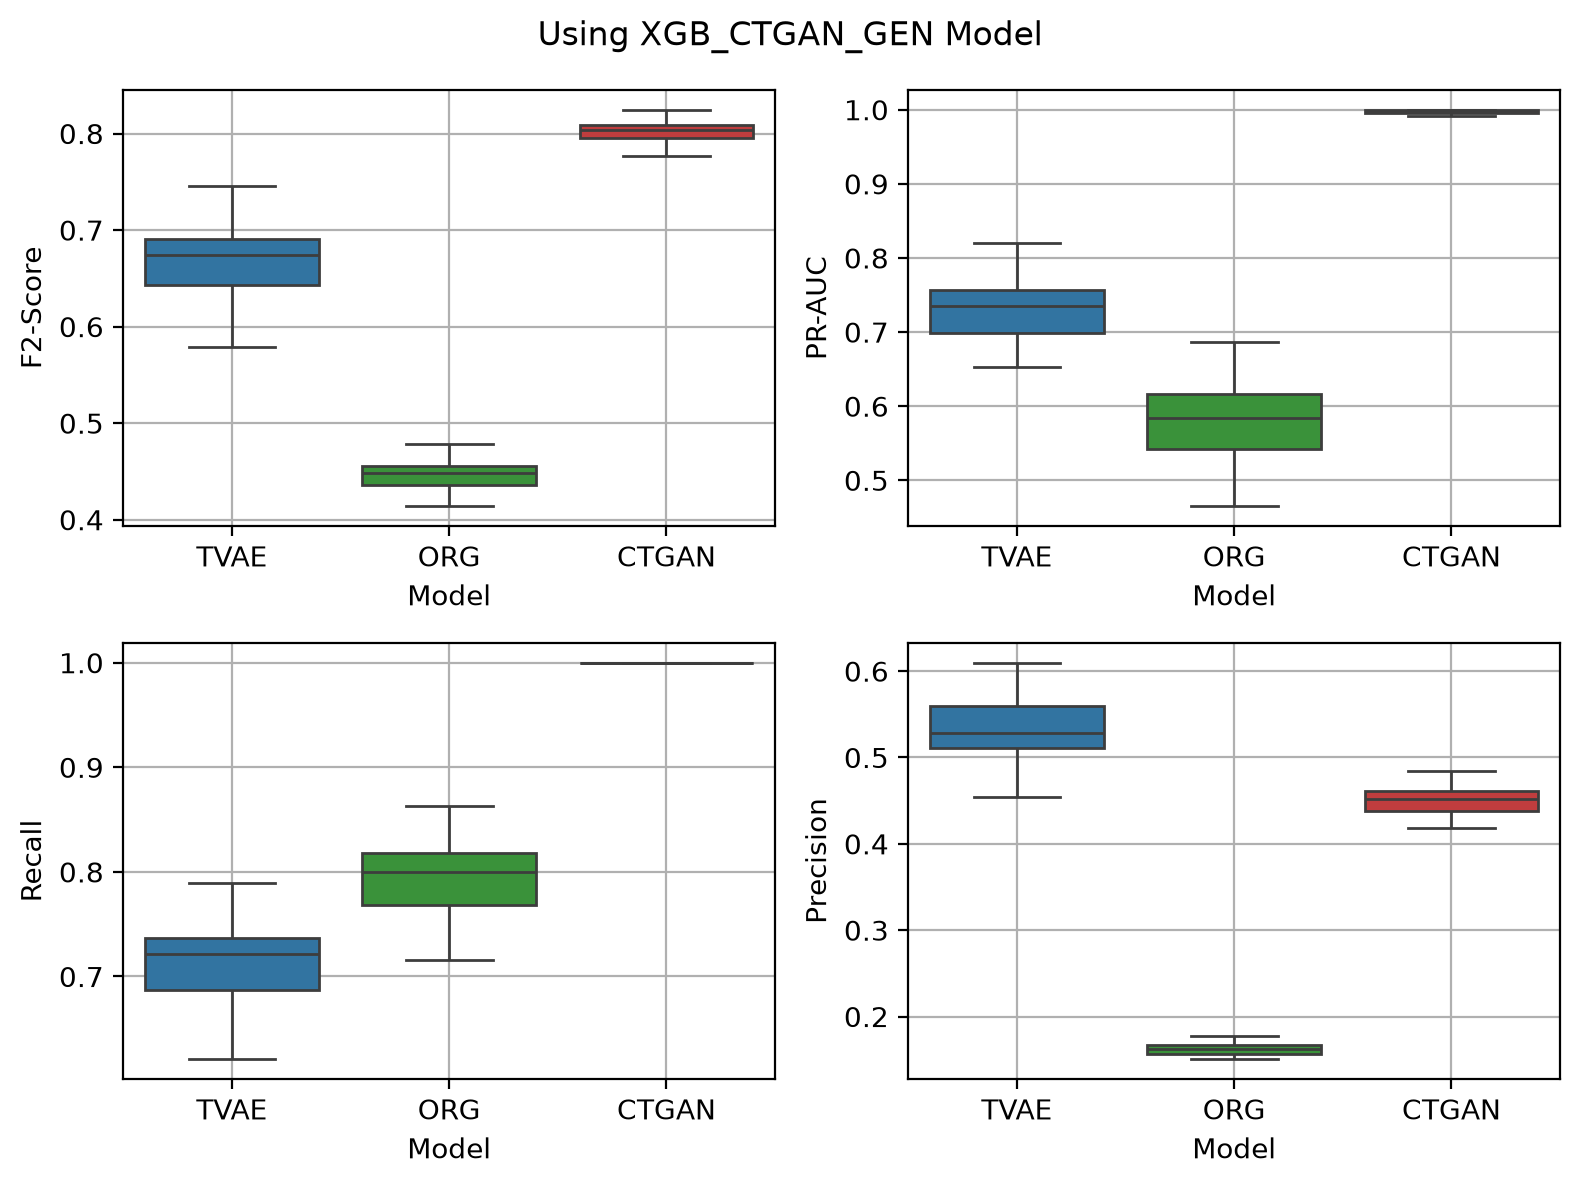

In [54]:
plot_metric_comparision(1,  model_list= model_list2,cols=cols, metric_dic = metric_dic2, order =order2)#, test_metrics_df=test_metrics_df2)

### NOTE
- When build model on Generated data it's kind of over-fitted to it's own generated data and cannot perform well on real data.
- It may need more work for future!

### Elapsed Time

In [55]:
# Calculate elapsed time
total_elapsed_time = time.time() - notebook_start_time
minutes = int(total_elapsed_time // 60)
seconds = total_elapsed_time % 60
print(f"Total Notebook Execution Time: {minutes} minutes and {seconds:.2f} seconds")

Total Notebook Execution Time: 7 minutes and 22.39 seconds


# Summary

1. We load the full cleaned dataset from step-1
2. Remove some generated duplicates due to grouping Hour to gether as Hour/2
3. Train 4 generative models: TVAE for minority, TVAE for majority, CTGAN for minority, and CTGAN for majority class
4. Using t-SNE, Check 2D map of generated data by generative models against map of real data
5. In all map we can see 2 main cluster (Fraud and Legit), but TVAE map more similar to real data (ORG), and CTGA has a more clean separated clusters
6. Visually check/compare distribution(box-plot) of generated data against real data for both minority and majority classes (difficult to select which one is better)
7. Numerically check/compare the quality of generated data by TVAE and CTGAN for both minority and majority, where TVAE seems a winner
8. We used all classification models which trained on real data (with/without oversampling) and checked their performance metrics on generated data by TVAE and CTGAN
9. Using a minimum threshold of `80%` on 4 major metrics in our fraud detection case (`F2-Score`, `PR-AUC`, `Recall`, `Precision`) our selection narrow down to single winner: CTGAN as generative model with classifier XGB_CTGAN.
10. we also check if we use generated data by generative model and train a classifier them, how these classifier perform on real data which was not promising at all, and it seems such a classifier easily overfit of its own training data, and cannot generalize unseen data (This was simple trial and may need more investigation in future).